# Stage 4 — Factor-Based Shock Simulator and Gymnasium Environment
Hybrid factor model + multivariate Student-t (factors and stock residuals) fitted on the training split, calibrated plausibility, bounded factor-shock simulator and the stress-testing environment. Ported from `src/rlstress/shocks/` and `src/rlstress/env.py`; results are compared with `results/stage4/`.

## 1. Imports and configuration

In [1]:
import json
import math
import re
import subprocess
import sys
import tomllib
import warnings
from dataclasses import dataclass, field, replace
from pathlib import Path

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
from gymnasium import spaces
from gymnasium.utils.env_checker import check_env
from scipy import stats
from scipy.special import gammaln

%matplotlib inline
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3dc", "grid.linewidth": 0.8})

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "default.toml").is_file()), None
)
assert PROJECT_ROOT is not None, "config/default.toml not found; run the notebook from inside the project"
with (PROJECT_ROOT / "config" / "default.toml").open("rb") as fh:
    CONFIG = tomllib.load(fh)

PORT, RISK, DATA, SIM, ENV_CFG = CONFIG["portfolio"], CONFIG["risk"], CONFIG["data"], CONFIG["simulation"], CONFIG["environment"]
WEIGHTS = pd.Series(PORT["weights"], dtype=float)
TICKERS = tuple(WEIGHTS.index)
CAPITAL = float(PORT["initial_capital"])
FACTORS = tuple(SIM["factors"])
MARKET = SIM["market_factor"]
SPLITS = {k: tuple(v) for k, v in DATA["splits"].items()}
FIT_START, FIT_END = SPLITS[SIM["fit_window"]]
HORIZON = int(SIM["horizon_days"])
PATH_METRICS = ("cumulative_loss", "max_drawdown")
RISK_METRIC_UNITS = {"cumulative_loss": "fraction_of_initial_value", "max_drawdown": "fraction_of_peak_value",
                     "historical_var": "fraction_of_portfolio_value", "historical_cvar": "fraction_of_portfolio_value"}
LIMITS = RISK["limits"]
STAGE4_RESULTS = PROJECT_ROOT / SIM["output_dir"]

assert list(TICKERS) == ["AAPL", "MSFT", "NVDA", "JPM", "XOM", "JNJ", "WMT", "CAT"]
assert [f.removesuffix("_return") for f in FACTORS] == ["SPY", "QQQ", "XLF", "XLE"]
assert SPLITS == {"train": ("2015-01-01", "2021-12-31"), "validation": ("2022-01-01", "2023-12-31"),
                  "test": ("2024-01-01", "2025-12-31")}
assert SIM["fit_window"] == "train" and SIM["anchor_window"] == "train"

COMPARE = []   # (item, notebook, existing implementation, max abs diff, match)
def compare(item, nb_value, ref_value, tol=1e-9):
    a, b = np.asarray(nb_value, dtype=float), np.asarray(ref_value, dtype=float)
    diff = float(np.max(np.abs(a - b))) if a.size else 0.0
    COMPARE.append({"item": item, "max_abs_diff": diff, "tolerance": tol, "match": a.shape == b.shape and diff <= tol})

print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | scipy {scipy.__version__} | gymnasium {gym.__version__}")
display(pd.DataFrame({
    "setting": ["stocks", "factors (market)", "weights", "capital", "fit window", "anchor window", "horizon days",
                "seed", "max_factor_sigma", "max_abs_factor_return", "max_abs_stock_return", "residual_mode",
                "min_plausibility", "surprisal_cap", "dof grid", "shrinkage"]
               + [f"limit {l['name']}" for l in LIMITS] + [f"env {k}" for k in ENV_CFG],
    "value": [", ".join(TICKERS), f"{', '.join(FACTORS)} ({MARKET})", ", ".join(f"{w:.3f}" for w in WEIGHTS),
              f"{CAPITAL:,.0f} {PORT['base_currency']}", f"{SIM['fit_window']} {FIT_START} -> {FIT_END}",
              SIM["anchor_window"], HORIZON, SIM["seed"], SIM["max_factor_sigma"], SIM["max_abs_factor_return"],
              SIM["max_abs_stock_return"], SIM["residual_mode"], SIM["min_plausibility"], SIM["surprisal_cap"],
              str(SIM["dof_grid"]), SIM["shrinkage_method"]]
             + [f"{l['metric']} {l['horizon_days']}d {l['breach_rule']} {l['threshold']:.0%}" for l in LIMITS]
             + [str(v) for v in ENV_CFG.values()],
}).style.hide(axis="index"))

Python 3.14.7 | numpy 2.5.4 | pandas 3.0.6 | scipy 1.18.1 | gymnasium 1.4.0


setting,value
stocks,"AAPL, MSFT, NVDA, JPM, XOM, JNJ, WMT, CAT"
factors (market),"SPY_return, QQQ_return, XLF_return, XLE_return (SPY_return)"
weights,"0.125, 0.125, 0.125, 0.125, 0.125, 0.125, 0.125, 0.125"
capital,"100,000 USD"
fit window,train 2015-01-01 -> 2021-12-31
anchor window,train
horizon days,5
seed,42
max_factor_sigma,12.000000
max_abs_factor_return,0.250000


## 2. Load historical data

In [2]:
SOURCE_PATH = PROJECT_ROOT / RISK["returns_path"]                 # Stage 2 consolidated dataset used by the engine
STAGE2_NB_PATH = PROJECT_ROOT / "data/processed/returns" / f"daily_returns_processed_{DATA['start_date']}_{DATA['end_date']}.csv"
missing_paths = [str(p) for p in [SOURCE_PATH] if not p.is_file()]
if missing_paths:
    raise FileNotFoundError(f"Required Stage 2 file(s) missing: {missing_paths}")

source = pd.read_csv(SOURCE_PATH, parse_dates=["date"], index_col="date")
STOCK_COLS = [PORT["return_column_template"].format(ticker=t) for t in TICKERS]
STATE_COLS = list(SIM["state_columns"])
needed = [*FACTORS, *STOCK_COLS, *STATE_COLS]
missing_cols = [c for c in needed if c not in source.columns]
numeric = source[needed]
checks = pd.DataFrame({
    "check": ["required columns present", "DatetimeIndex", "dates sorted", "duplicate dates",
              "non-numeric columns", "infinite values", "returns <= -100%", "rows with any missing value"],
    "result": [not missing_cols, isinstance(source.index, pd.DatetimeIndex), source.index.is_monotonic_increasing,
               int(source.index.duplicated().sum()), [c for c in needed if not pd.api.types.is_numeric_dtype(source[c])],
               int(np.isinf(numeric.to_numpy()).sum()), int((source[[*FACTORS, *STOCK_COLS]] <= -1).sum().sum()),
               int(numeric.isna().any(axis=1).sum())],
})
display(checks.style.hide(axis="index"))
assert not missing_cols, f"missing columns: {missing_cols}"
assert source.index.is_monotonic_increasing and source.index.is_unique
assert not np.isinf(numeric.to_numpy()).any() and not (source[[*FACTORS, *STOCK_COLS]] <= -1).any().any()

print(f"Loaded {SOURCE_PATH.relative_to(PROJECT_ROOT)}: {source.shape[0]} rows x {source.shape[1]} columns, "
      f"{source.index.min().date()} -> {source.index.max().date()}")
display(numeric.isna().sum().to_frame("missing").T)
if STAGE2_NB_PATH.is_file():
    s2 = pd.read_csv(STAGE2_NB_PATH, parse_dates=["date"], index_col="date")
    same = s2.index.equals(source.index) and s2[[*FACTORS, *STOCK_COLS]].equals(source[[*FACTORS, *STOCK_COLS]])
    print(f"Return columns identical to stage_2.ipynb output ({STAGE2_NB_PATH.name}): {same}")
    assert same

check,result
required columns present,True
DatetimeIndex,True
dates sorted,True
duplicate dates,0
non-numeric columns,[]
infinite values,0
returns <= -100%,0
rows with any missing value,16


Loaded data/processed/features/consolidated_daily.csv: 2766 rows x 165 columns, 2015-01-02 -> 2025-12-31


,SPY_return,QQQ_return,XLF_return,XLE_return,AAPL_return,MSFT_return,NVDA_return,JPM_return,XOM_return,JNJ_return,WMT_return,CAT_return,VIX_close,SPY_vol_ann_20d
missing,1,1,1,1,1,1,1,1,1,1,1,1,0,16


Return columns identical to stage_2.ipynb output (daily_returns_processed_2015-01-01_2025-12-31.csv): True


## 3. Prepare training data

In [3]:
def select_window(frame, start, end):
    mask = np.ones(len(frame), dtype=bool)
    if start is not None:
        mask &= frame.index >= pd.Timestamp(start)
    if end is not None:
        mask &= frame.index <= pd.Timestamp(end)
    return frame[mask]

def training_matrix(src, tickers, factors, start, end):
    """Complete-case factor and stock returns inside [start, end] only."""
    cols = [f"{t}_return" for t in tickers]
    window = select_window(src[[*factors, *cols]], start, end)
    complete = window.dropna()
    if complete.index.max() > pd.Timestamp(end) or complete.index.min() < pd.Timestamp(start):
        raise ValueError("training matrix leaked outside the fit window")
    stocks = complete[cols].copy()
    stocks.columns = list(tickers)
    return complete[list(factors)], stocks, int(len(window) - len(complete))

train_f, train_r, n_excluded = training_matrix(source, TICKERS, FACTORS, FIT_START, FIT_END)
validation_data = select_window(source[[*FACTORS, *STOCK_COLS]], *SPLITS["validation"])
test_data = select_window(source[[*FACTORS, *STOCK_COLS]], *SPLITS["test"])

print(f"Training (fit) data: factors {train_f.shape}, stocks {train_r.shape}; "
      f"{train_f.index.min().date()} -> {train_f.index.max().date()}; incomplete rows excluded: {n_excluded}")
print(f"Held out: validation {validation_data.shape} {validation_data.index.min().date()} -> {validation_data.index.max().date()}, "
      f"test {test_data.shape} {test_data.index.min().date()} -> {test_data.index.max().date()}")
summary = pd.concat([train_f, train_r], axis=1).describe().T
display((summary[["mean", "std", "min", "25%", "50%", "75%", "max"]] * 100).round(3).assign(
    count=summary["count"].astype(int)).rename(columns=lambda c: c if c == "count" else f"{c} (%)"))

assert train_f.index.max() <= pd.Timestamp(FIT_END) and train_f.index.min() >= pd.Timestamp(FIT_START)
assert not set(train_f.index) & set(validation_data.index), "validation dates in fit data"
assert not set(train_f.index) & set(test_data.index), "test dates in fit data"
print("No validation or test dates in the fitting dataset.")

Training (fit) data: factors (1762, 4), stocks (1762, 8); 2015-01-05 -> 2021-12-31; incomplete rows excluded: 1
Held out: validation (501, 12) 2022-01-03 -> 2023-12-29, test (502, 12) 2024-01-02 -> 2025-12-31


,mean (%),std (%),min (%),25% (%),50% (%),75% (%),max (%),count
SPY_return,0.061,1.113,-10.942,-0.322,0.067,0.550,9.060,1762
QQQ_return,0.089,1.321,-11.979,-0.432,0.134,0.742,8.471,1762
XLF_return,0.056,1.480,-13.709,-0.550,0.075,0.742,13.157,1762
XLE_return,0.016,1.962,-20.141,-0.830,0.000,0.861,16.037,1762
AAPL,0.129,1.828,-12.865,-0.657,0.095,1.022,11.981,1762
MSFT,0.134,1.698,-14.739,-0.590,0.098,0.915,14.217,1762
NVDA,0.274,2.866,-18.756,-1.063,0.252,1.641,29.807,1762
JPM,0.079,1.785,-14.965,-0.703,0.033,0.866,18.012,1762
XOM,0.011,1.763,-12.225,-0.791,-0.012,0.779,12.687,1762
JNJ,0.046,1.180,-10.038,-0.464,0.055,0.602,7.998,1762


No validation or test dates in the fitting dataset.


## 4. Factor correlation analysis

,SPY,QQQ,XLF,XLE
SPY,1.0000,0.9206,0.8638,0.7069
QQQ,0.9206,1.0000,0.6673,0.5130
XLF,0.8638,0.6673,1.0000,0.7527
XLE,0.7069,0.5130,0.7527,1.0000


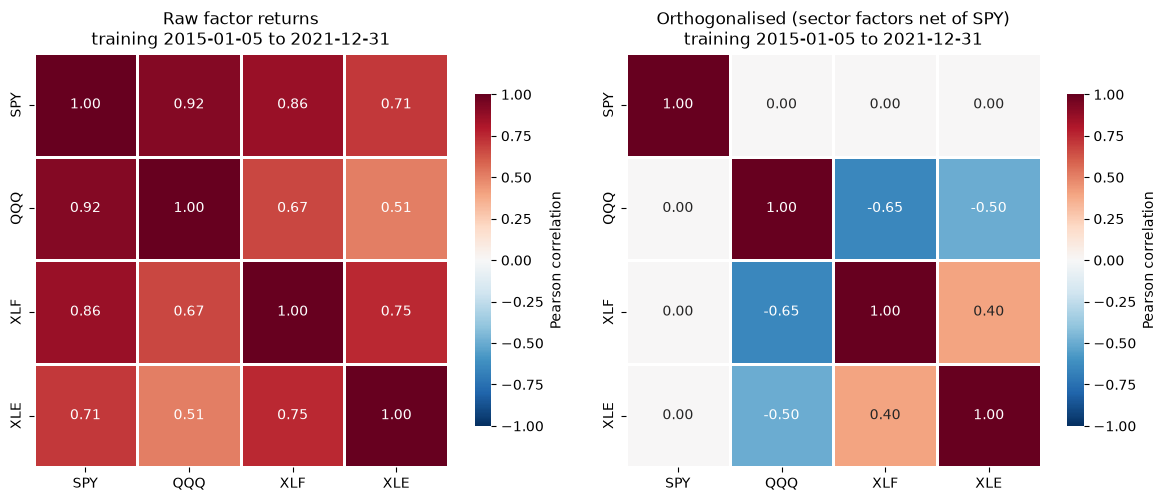

factor,orth_intercept_c,orth_slope_on_SPY_h,VIF_raw,VIF_orthogonalised
SPY_return,0.00e+00,0.0000,29.03,1.00
QQQ_return,2.19e-04,1.0920,12.90,1.97
XLF_return,-1.38e-04,1.1481,6.92,1.76
XLE_return,-6.07e-04,1.2459,2.69,1.35


Condition number of factor covariance: raw 227.3 -> orthogonalised 18.8


In [4]:
def ols(y, x):
    """OLS with intercept: (coefficients with intercept first, residuals)."""
    design = np.column_stack([np.ones(len(x)), x])
    coef, *_ = np.linalg.lstsq(design, y, rcond=None)
    return coef, y - design @ coef

def variance_inflation(x):
    out = []
    for j in range(x.shape[1]):
        _, resid = ols(x[:, j], np.delete(x, j, axis=1))
        r2 = 1 - resid.var() / x[:, j].var()
        out.append(float(1 / (1 - r2)) if r2 < 1 else float("inf"))
    return out

factor_corr = train_f.corr()
short = lambda c: c.removesuffix("_return")
display(factor_corr.rename(index=short, columns=short).round(4))

# Existing transformation: non-market factors are orthogonalised against SPY by OLS on training data.
F = train_f.to_numpy(dtype=float)
K, N = len(FACTORS), len(TICKERS)
M_IDX = FACTORS.index(MARKET)
orth_c, orth_h, G = np.zeros(K), np.zeros(K), F.copy()
for j in range(K):
    if j != M_IDX:
        coef, resid = ols(F[:, j], F[:, [M_IDX]])
        orth_c[j], orth_h[j] = coef
        G[:, j] = resid
orth_corr = pd.DataFrame(np.corrcoef(G, rowvar=False), index=FACTORS, columns=FACTORS)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, mat, title in [(axes[0], factor_corr, "Raw factor returns"), (axes[1], orth_corr, "Orthogonalised (sector factors net of SPY)")]:
    sns.heatmap(mat.rename(index=short, columns=short), vmin=-1, vmax=1, center=0, cmap="RdBu_r", annot=True, fmt=".2f",
                square=True, linewidths=1, linecolor="white", cbar_kws={"label": "Pearson correlation", "shrink": 0.8}, ax=ax)
    ax.grid(False)
    ax.set_title(f"{title}\ntraining {train_f.index.min().date()} to {train_f.index.max().date()}")
plt.tight_layout()
plt.show()

display(pd.DataFrame({"factor": FACTORS, "orth_intercept_c": orth_c, "orth_slope_on_SPY_h": orth_h,
                      "VIF_raw": variance_inflation(F), "VIF_orthogonalised": variance_inflation(G)}).style.hide(axis="index")
        .format({"orth_intercept_c": "{:.2e}", "orth_slope_on_SPY_h": "{:.4f}", "VIF_raw": "{:.2f}", "VIF_orthogonalised": "{:.2f}"}))
print(f"Condition number of factor covariance: raw {np.linalg.cond(np.cov(F, rowvar=False)):.1f} -> "
      f"orthogonalised {np.linalg.cond(np.cov(G, rowvar=False)):.1f}")

## 5. Fit the factor model

In [5]:
R = train_r.to_numpy(dtype=float)
coef, RESID = ols(R, G)                         # r_i = alpha_i + beta_i' g + e_i
alpha, beta = coef[0], coef[1:].T               # (n,), (n, k)
A = np.eye(K)
A[:, M_IDX] -= orth_h                           # g = A f - c
raw_loadings = beta @ A                         # r = a + B f + e
raw_intercept = alpha - beta @ orth_c
r2 = 1 - RESID.var(axis=0) / R.var(axis=0)

loadings = pd.DataFrame(beta, index=TICKERS, columns=[f"beta_{short(f)}_orth" for f in FACTORS])
loadings_raw = pd.DataFrame(raw_loadings, index=TICKERS, columns=[f"B_{short(f)}_raw" for f in FACTORS])
resid_corr = np.corrcoef(RESID, rowvar=False)
off = ~np.eye(N, dtype=bool)
fit_table = pd.concat([loadings, loadings_raw], axis=1).assign(
    alpha_daily=alpha, R_squared=r2,
    resid_sd_daily_pct=RESID.std(axis=0, ddof=1) * 100,
    resid_excess_kurtosis=((RESID - RESID.mean(0)) ** 4).mean(0) / RESID.var(0) ** 2 - 3.0,
    resid_lag1_autocorr=[np.corrcoef(RESID[1:, i], RESID[:-1, i])[0, 1] for i in range(N)])
display(fit_table.style.format("{:.4f}").format({"alpha_daily": "{:.2e}"}))
print(f"Residual correlation between stocks: max |rho| {np.abs(resid_corr[off]).max():.3f}, "
      f"mean |rho| {np.abs(resid_corr[off]).mean():.3f} (kept in the joint Student-t scatter)")

# Compare with the existing implementation's saved fit (results/stage4).
REF = json.loads((STAGE4_RESULTS / "shock_model.json").read_text())
REF_DIAG = json.loads((STAGE4_RESULTS / "shock_model_diagnostics.json").read_text())
compare("orthogonalisation c, h", np.r_[orth_c, orth_h], np.r_[REF["orth_intercept"], REF["orth_slope"]], 1e-12)
compare("alpha (orth)", alpha, REF["alpha"], 1e-12)
compare("beta (orth loadings)", beta, REF["beta"], 1e-10)
compare("raw intercept a", raw_intercept, REF["raw_intercept"], 1e-12)
compare("raw loadings B", raw_loadings, REF["raw_loadings"], 1e-10)
compare("R-squared (rounded 6dp in source)", r2.round(6), [REF["diagnostics"]["r_squared"][t] for t in TICKERS], 1e-12)
compare("VIF raw / orth (rounded 3dp)", np.r_[np.round(variance_inflation(F), 3), np.round(variance_inflation(G), 3)],
        np.r_[[REF["diagnostics"]["vif_raw_factors"][f] for f in FACTORS], [REF["diagnostics"]["vif_orthogonalised_factors"][f] for f in FACTORS]], 1e-9)
display(pd.DataFrame(COMPARE).style.hide(axis="index").format({"max_abs_diff": "{:.2e}", "tolerance": "{:.0e}"}))

,beta_SPY_orth,beta_QQQ_orth,beta_XLF_orth,beta_XLE_orth,B_SPY_raw,B_QQQ_raw,B_XLF_raw,B_XLE_raw,alpha_daily,R_squared,resid_sd_daily_pct,resid_excess_kurtosis,resid_lag1_autocorr
AAPL,1.205468,1.312962,-0.016517,0.007644,-0.218852,1.312962,-0.016517,0.007644,5.48e-04,0.677254,1.038591,6.646197,0.042687
MSFT,1.217115,1.081975,-0.028873,-0.045267,0.125139,1.081975,-0.028873,-0.045267,5.91e-04,0.764306,0.824351,15.617653,-0.036627
NVDA,1.541748,2.175440,0.115192,0.055851,-1.035675,2.175440,0.115192,0.055851,1.80e-03,0.488460,2.049589,34.969071,-0.025485
JPM,1.223207,0.200133,1.418840,0.043924,-0.678999,0.200133,1.418840,0.043924,4.34e-05,0.907897,0.541572,5.259462,-0.076334
XOM,1.033070,-0.212960,-0.061969,0.777836,0.367684,-0.212960,-0.061969,0.777836,-5.26e-04,0.828087,0.731116,7.342664,0.013398
JNJ,0.668165,-0.859362,-0.363107,-0.159650,2.222370,-0.859362,-0.363107,-0.159650,4.78e-05,0.478531,0.851867,10.837767,-0.034494
WMT,0.561508,-0.543751,-0.307544,-0.194716,1.750961,-0.543751,-0.307544,-0.194716,1.32e-04,0.268422,1.149996,16.666687,-0.005154
CAT,1.143531,-0.262323,0.240904,0.236720,0.858491,-0.262323,0.240904,0.236720,5.60e-05,0.537351,1.279862,6.070452,-0.003656


Residual correlation between stocks: max |rho| 0.125, mean |rho| 0.041 (kept in the joint Student-t scatter)


item,max_abs_diff,tolerance,match
"orthogonalisation c, h",0.00e+00,1e-12,True
alpha (orth),0.00e+00,1e-12,True
beta (orth loadings),0.00e+00,1e-10,True
raw intercept a,0.00e+00,1e-12,True
raw loadings B,0.00e+00,1e-10,True
R-squared (rounded 6dp in source),0.00e+00,1e-12,True
VIF raw / orth (rounded 3dp),0.00e+00,1e-09,True


## 6. Fit the multivariate Student-t shock model

nu,joint_loglik,joint_converged,joint_iter,factor_loglik,factor_converged,factor_iter
2.500000,"71,444.20",True,71,"24,883.43",True,39
3.000000,"71,503.69",True,60,"24,903.03",True,33
3.500000,"71,538.20",True,52,"24,908.72",True,29
4.000000,"71,556.24",True,46,"24,906.30",True,22
4.500000,"71,562.99",True,41,"24,899.01",True,24
5.000000,"71,561.76",True,36,"24,888.78",True,23
6.000000,"71,543.63",True,32,"24,863.77",True,22
7.000000,"71,512.87",True,31,"24,836.50",True,21
8.000000,"71,475.25",True,29,"24,809.16",True,20
10.000000,"71,391.16",True,26,"24,757.59",True,18


model,dimension,nu,shrinkage (Schafer-Strimmer),loglik,EM iterations,converged,scatter condition number
joint t (factors + residuals),12,4.500000,0.0368,"71,562.988",41,True,71.6
factor-only t (plausibility),4,3.500000,0.0136,"24,908.723",29,True,102.0


,SPY,QQQ,XLF,XLE,e_AAPL,e_MSFT,e_NVDA,e_JPM,e_XOM,e_JNJ,e_WMT,e_CAT
location_mu_daily,0.00089,0.00131,0.00073,-0.00004,-0.00009,-0.00018,-0.00049,-0.00009,-0.00011,-0.00004,-0.00013,-0.00010
model_sd_daily_pct,1.05563,1.33003,1.41023,1.94628,1.16652,0.87499,2.10000,0.60794,0.81286,0.91771,1.16401,1.42839


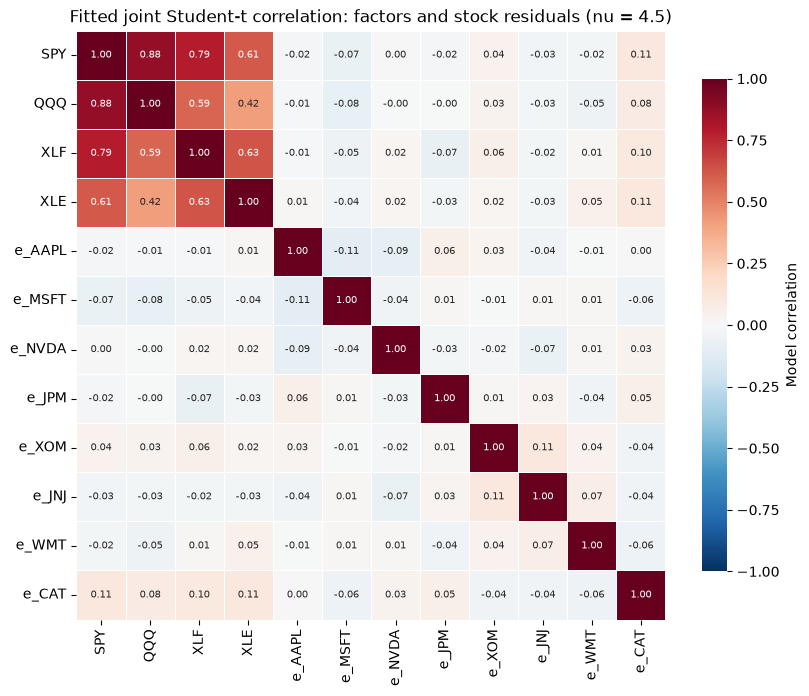

Factor action bounds |a| = 1: {'SPY': '12.67%', 'QQQ': '15.96%', 'XLF': '16.92%', 'XLE': '23.36%'}


item,max_abs_diff,tolerance,match
joint t: nu,0.00e+00,0e+00,True
joint t: shrinkage,0.00e+00,1e-14,True
joint t: location mu,0.00e+00,1e-12,True
joint t: scatter Sigma,0.00e+00,1e-12,True
joint t: loglik,0.00e+00,1e-06,True
"factor t: nu, shrinkage",0.00e+00,1e-14,True
"factor t: mu, Sigma",0.00e+00,1e-12,True
path calibration (5 lengths),0.00e+00,1e-09,True


In [6]:
def mahalanobis_sq(x, mu, sigma):
    chol = np.linalg.cholesky(sigma)
    z = np.linalg.solve(chol, (np.atleast_2d(x) - mu).T)
    out = np.sum(z * z, axis=0)
    return out if np.ndim(x) > 1 else out[0]

def mvt_logpdf(x, mu, sigma, nu):
    d = len(mu)
    logdet = 2.0 * np.sum(np.log(np.diag(np.linalg.cholesky(sigma))))
    maha = mahalanobis_sq(np.atleast_2d(x), mu, sigma)
    return (gammaln((nu + d) / 2) - gammaln(nu / 2) - d / 2 * np.log(nu * np.pi)
            - 0.5 * logdet - (nu + d) / 2 * np.log1p(maha / nu))

def schafer_strimmer_intensity(x):
    """Optimal shrinkage of the correlation matrix towards the identity (Schafer & Strimmer 2005)."""
    n = x.shape[0]
    z = (x - x.mean(axis=0)) / x.std(axis=0, ddof=1)
    w = z[:, :, None] * z[:, None, :]
    w_bar = w.mean(axis=0)
    r = n / (n - 1) * w_bar
    var_r = n / (n - 1) ** 3 * ((w - w_bar) ** 2).sum(axis=0)
    off_ = ~np.eye(x.shape[1], dtype=bool)
    denom = float((r[off_] ** 2).sum())
    return 1.0 if denom == 0 else float(np.clip(var_r[off_].sum() / denom, 0.0, 1.0))

def shrink_to_diagonal(s, lam):
    return (1.0 - lam) * s + lam * np.diag(np.diag(s))

@dataclass
class MVTFit:
    mu: np.ndarray
    sigma: np.ndarray
    nu: float
    loglik: float
    n_iter: int
    converged: bool
    shrinkage: float
    grid: list = field(default_factory=list)

def fit_mvt_em(x, nu, shrinkage, max_iter, tol):
    """EM for fixed nu (Liu & Rubin 1995) with shrinkage of the scatter towards its diagonal."""
    n, d = x.shape
    mu = x.mean(axis=0)
    sigma = shrink_to_diagonal(np.cov(x, rowvar=False, ddof=1) * (nu - 2) / nu, shrinkage)
    prev, converged, it = -np.inf, False, 0
    for it in range(1, max_iter + 1):
        w = (nu + d) / (nu + mahalanobis_sq(x, mu, sigma))
        mu = (w[:, None] * x).sum(axis=0) / w.sum()
        diff = x - mu
        sigma = shrink_to_diagonal((w[:, None] * diff).T @ diff / n, shrinkage)
        ll = float(mvt_logpdf(x, mu, sigma, nu).sum())
        if abs(ll - prev) <= tol * max(1.0, abs(ll)):
            converged = True
            break
        prev = ll
    return MVTFit(mu, sigma, float(nu), ll, it, converged, shrinkage)

def fit_mvt(x, dof_grid, shrinkage, max_iter, tol):
    """Profile likelihood over the dof grid; keep the best."""
    fits = [fit_mvt_em(x, nu, shrinkage, max_iter, tol) for nu in dof_grid]
    best = max(fits, key=lambda f: f.loglik)
    best.grid = [{"nu": f.nu, "loglik": f.loglik, "converged": f.converged, "iterations": f.n_iter} for f in fits]
    return best

Z = np.column_stack([F, RESID])                  # joint (factors, stock residuals), 12 dims
shrink_joint = schafer_strimmer_intensity(Z) if SIM["shrinkage_method"] == "schafer_strimmer" else SIM["fixed_shrinkage"]
joint = fit_mvt(Z, SIM["dof_grid"], shrink_joint, SIM["em_max_iter"], SIM["em_tol"])
shrink_f = schafer_strimmer_intensity(F) if SIM["shrinkage_method"] == "schafer_strimmer" else SIM["fixed_shrinkage"]
plaus = fit_mvt(F, SIM["dof_grid"], shrink_f, SIM["em_max_iter"], SIM["em_tol"])   # factor-only t (plausibility)

day_surprisal = -stats.f.logsf(mahalanobis_sq(F, plaus.mu, plaus.sigma) / K, K, plaus.nu)
path_calibration = {str(t): np.sort(stats.gamma.logsf(np.convolve(day_surprisal, np.ones(t), mode="valid"), a=t)).tolist()
                    for t in range(1, HORIZON + 1)}

@dataclass
class ShockModel:
    tickers: tuple
    factors: tuple
    market_factor: str
    orth_intercept: np.ndarray
    orth_slope: np.ndarray
    raw_intercept: np.ndarray
    raw_loadings: np.ndarray
    mu: np.ndarray
    sigma: np.ndarray
    nu: float
    plaus_mu: np.ndarray
    plaus_sigma: np.ndarray
    plaus_nu: float
    path_calibration: dict

    @property
    def k(self):
        return len(self.factors)

    @property
    def factor_sd(self):
        """Model sd of each factor, sqrt(nu/(nu-2) Sigma_jj) from the joint t."""
        return np.sqrt(np.diag(self.sigma[: self.k, : self.k]) * self.nu / (self.nu - 2.0))

    def expected_returns(self, f):
        return self.raw_intercept + self.raw_loadings @ np.asarray(f, dtype=float)

model = ShockModel(TICKERS, FACTORS, MARKET, orth_c, orth_h, raw_intercept, raw_loadings,
                   joint.mu, joint.sigma, joint.nu, plaus.mu, plaus.sigma, plaus.nu, path_calibration)

grid = pd.DataFrame(joint.grid).rename(columns={"loglik": "joint_loglik", "converged": "joint_converged", "iterations": "joint_iter"})
pgrid = pd.DataFrame(plaus.grid).rename(columns={"loglik": "factor_loglik", "converged": "factor_converged", "iterations": "factor_iter"})
display(grid.merge(pgrid, on="nu").style.hide(axis="index").format({"joint_loglik": "{:,.2f}", "factor_loglik": "{:,.2f}"})
        .set_caption("Profile likelihood over the degrees-of-freedom grid (EM per nu)"))
display(pd.DataFrame({
    "model": ["joint t (factors + residuals)", "factor-only t (plausibility)"],
    "dimension": [Z.shape[1], F.shape[1]], "nu": [joint.nu, plaus.nu],
    "shrinkage (Schafer-Strimmer)": [shrink_joint, shrink_f], "loglik": [joint.loglik, plaus.loglik],
    "EM iterations": [joint.n_iter, plaus.n_iter], "converged": [joint.converged, plaus.converged],
    "scatter condition number": [np.linalg.cond(joint.sigma), np.linalg.cond(plaus.sigma)],
}).style.hide(axis="index").format({"shrinkage (Schafer-Strimmer)": "{:.4f}", "loglik": "{:,.3f}", "scatter condition number": "{:.1f}"}))

names = [short(f) for f in FACTORS] + [f"e_{t}" for t in TICKERS]
cov_joint = joint.sigma * joint.nu / (joint.nu - 2)
sd = np.sqrt(np.diag(cov_joint))
corr_joint = pd.DataFrame(cov_joint / np.outer(sd, sd), index=names, columns=names)
display(pd.DataFrame({"location_mu_daily": joint.mu, "model_sd_daily_pct": sd * 100}, index=names).T.style.format("{:.5f}"))
fig, ax = plt.subplots(figsize=(9.5, 8))
sns.heatmap(corr_joint, vmin=-1, vmax=1, center=0, cmap="RdBu_r", annot=True, fmt=".2f", annot_kws={"fontsize": 7},
            square=True, linewidths=0.5, linecolor="white", cbar_kws={"label": "Model correlation", "shrink": 0.8}, ax=ax)
ax.grid(False)
ax.set_title(f"Fitted joint Student-t correlation: factors and stock residuals (nu = {joint.nu})")
plt.show()
print("Factor action bounds |a| = 1:", {short(f): f"{b:.2%}" for f, b in zip(FACTORS, np.minimum(SIM["max_factor_sigma"] * model.factor_sd, SIM["max_abs_factor_return"]))})

compare("joint t: nu", joint.nu, REF["nu"], 0)
compare("joint t: shrinkage", shrink_joint, REF["shrinkage"], 1e-14)
compare("joint t: location mu", joint.mu, REF["mu"], 1e-12)
compare("joint t: scatter Sigma", joint.sigma, REF["sigma"], 1e-12)
compare("joint t: loglik", joint.loglik, REF["loglik"], 1e-6)
compare("factor t: nu, shrinkage", [plaus.nu, shrink_f], [REF["plaus_nu"], REF["plaus_shrinkage"]], 1e-14)
compare("factor t: mu, Sigma", np.r_[plaus.mu, plaus.sigma.ravel()], np.r_[REF["plaus_mu"], np.ravel(REF["plaus_sigma"])], 1e-12)
compare("path calibration (5 lengths)", np.concatenate([path_calibration[k] for k in sorted(path_calibration)]),
        np.concatenate([REF["path_calibration"][k] for k in sorted(REF["path_calibration"])]), 1e-9)
display(pd.DataFrame(COMPARE[-8:]).style.hide(axis="index").format({"max_abs_diff": "{:.2e}", "tolerance": "{:.0e}"}))

## 7. Validate simulated distributions
All “simulated” series below are model draws, not historical returns.

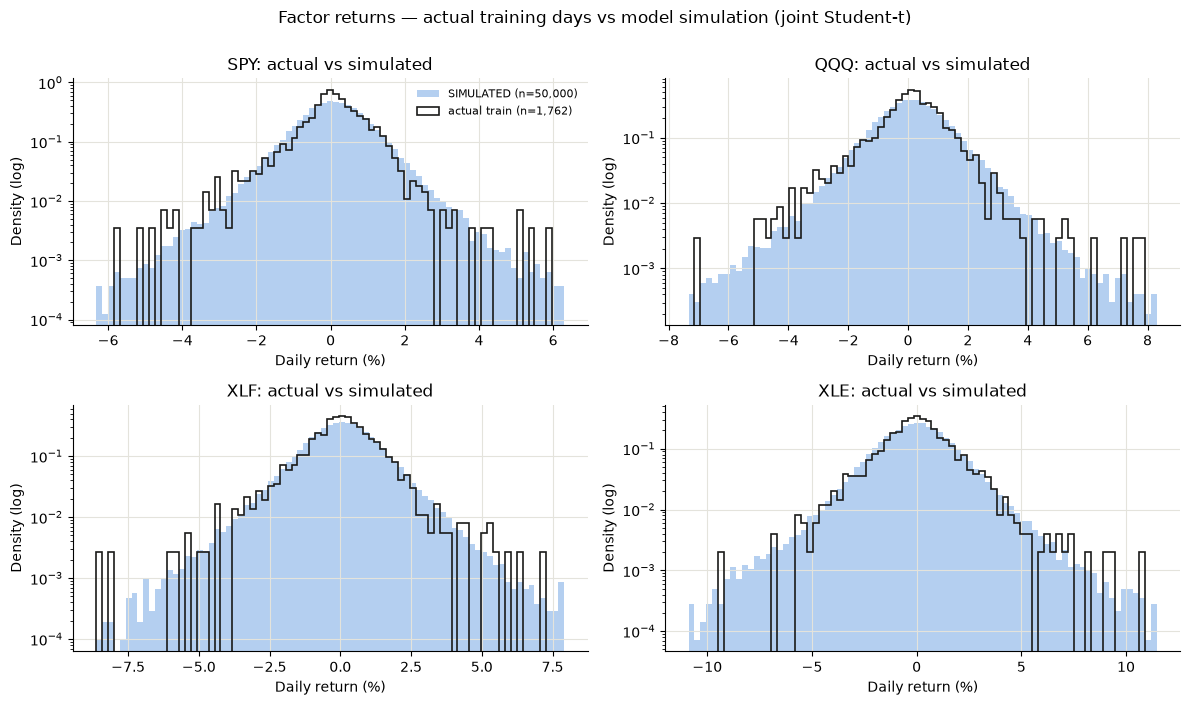

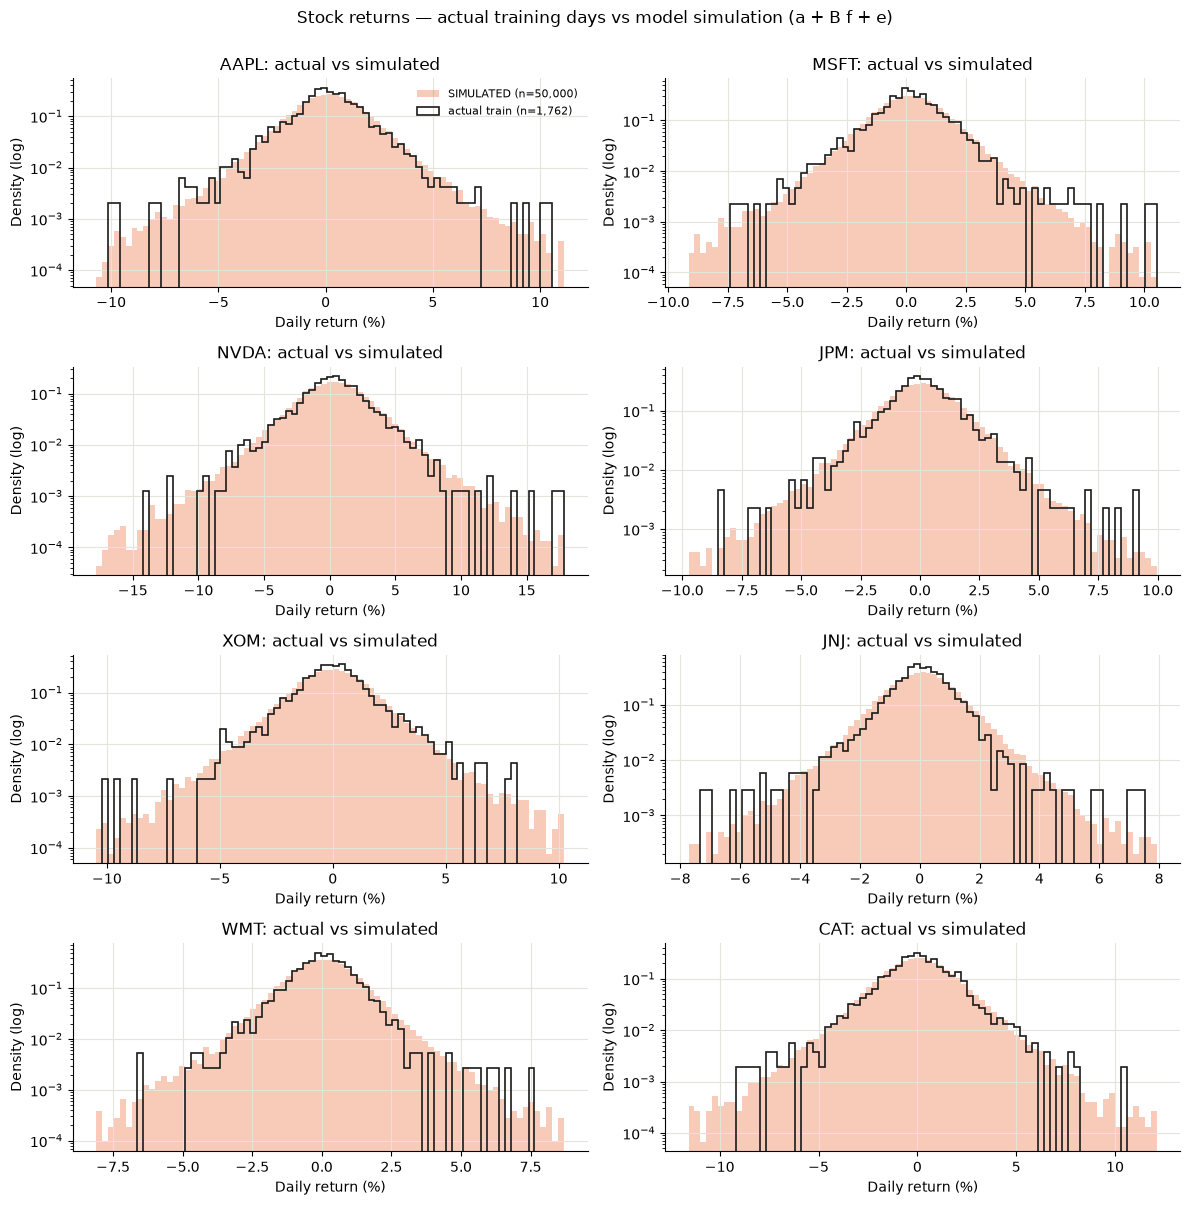

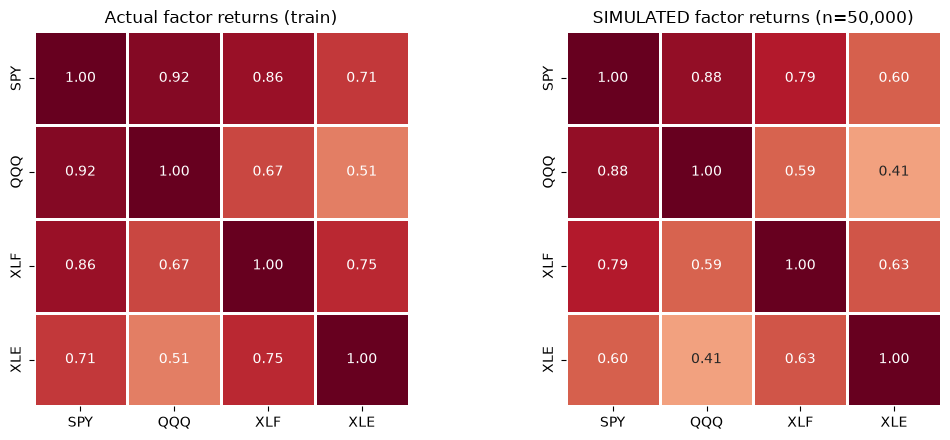

item,max_abs_diff,tolerance,match
"simulated per-stock sd (seed 42, 50,000 draws)",0.00e+00,1e-12,True
simulated per-stock 1% quantile,0.00e+00,1e-12,True
simulated portfolio VaR/CVaR 95/99,6.94e-18,1e-12,True


In [7]:
def sample_mvt(rng, mu, sigma, nu, size):
    """mu + Z / sqrt(W), Z ~ N(0, Sigma), W ~ chi2_nu / nu."""
    z = rng.multivariate_normal(np.zeros(len(mu)), sigma, size=size, method="cholesky")
    w = rng.chisquare(nu, size=size) / nu
    return mu + z / np.sqrt(w)[:, None]

def sample_days(model, rng, n):
    """n unconditional model days from the joint t: (factor returns, stock returns)."""
    z = sample_mvt(rng, model.mu, model.sigma, model.nu, n)
    f, e = z[:, : model.k], z[:, model.k:]
    return f, model.raw_intercept + f @ model.raw_loadings.T + e

N_SIM = int(SIM["diagnostic_simulations"])
sim_f, sim_r = sample_days(model, np.random.default_rng(SIM["seed"]), N_SIM)
sim_f = pd.DataFrame(sim_f, columns=FACTORS)
sim_r = pd.DataFrame(sim_r, columns=TICKERS)

def tail_mass(n, a):
    return round(n * (1.0 - a), 9)
def hist_var(x, a):
    x = np.sort(np.asarray(x, dtype=float))
    return -float(x[max(1, math.ceil(tail_mass(len(x), a))) - 1])
def hist_cvar(x, a):
    x = np.sort(np.asarray(x, dtype=float))
    m = tail_mass(len(x), a); j = math.floor(m); b = round(m - j, 9)
    return -(float(x[:j].sum()) + (b * float(x[j]) if b > 0 else 0.0)) / m

def describe(x):
    x = np.asarray(x, dtype=float)
    return {"mean_%": x.mean() * 100, "sd_%": x.std(ddof=1) * 100, "q95_|r|_%": np.quantile(np.abs(x), 0.95) * 100,
            "q99_|r|_%": np.quantile(np.abs(x), 0.99) * 100, "q01_%": np.quantile(x, 0.01) * 100,
            "VaR99_%": hist_var(x, 0.99) * 100, "CVaR99_%": hist_cvar(x, 0.99) * 100,
            "excess_kurtosis": stats.kurtosis(x)}

rows = []
for col, actual, simulated in [*[(short(f), train_f[f], sim_f[f]) for f in FACTORS], *[(t, train_r[t], sim_r[t]) for t in TICKERS],
                               ("PORTFOLIO", train_r[list(TICKERS)] @ WEIGHTS, sim_r[list(TICKERS)] @ WEIGHTS)]:
    rows.append({"series": col, "source": "actual (train)", "n": len(actual), **describe(actual)})
    rows.append({"series": col, "source": "SIMULATED", "n": len(simulated), **describe(simulated)})
dist_table = pd.DataFrame(rows).set_index(["series", "source"])
display(dist_table.style.format("{:.3f}").format({"n": "{:,.0f}"}))

def overlay(ax, actual, simulated, title, color):
    lo, hi = np.quantile(np.r_[actual, simulated], [0.0005, 0.9995])
    bins = np.linspace(lo, hi, 80)
    ax.hist(simulated * 100, bins=bins * 100, density=True, color=color, alpha=0.35, label=f"SIMULATED (n={len(simulated):,})")
    ax.hist(actual * 100, bins=bins * 100, density=True, histtype="step", color="#1a1a19", linewidth=1.2, label=f"actual train (n={len(actual):,})")
    ax.set_yscale("log")
    ax.set_title(title)
    ax.set_xlabel("Daily return (%)")
    ax.set_ylabel("Density (log)")

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, f in zip(axes.flat, FACTORS):
    overlay(ax, train_f[f].to_numpy(), sim_f[f].to_numpy(), f"{short(f)}: actual vs simulated", "#2a78d6")
axes.flat[0].legend(frameon=False, fontsize=8)
fig.suptitle("Factor returns — actual training days vs model simulation (joint Student-t)", y=1.0)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(4, 2, figsize=(12, 12))
for ax, t in zip(axes.flat, TICKERS):
    overlay(ax, train_r[t].to_numpy(), sim_r[t].to_numpy(), f"{t}: actual vs simulated", "#eb6834")
axes.flat[0].legend(frameon=False, fontsize=8)
fig.suptitle("Stock returns — actual training days vs model simulation (a + B f + e)", y=1.0)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, mat, title in [(axes[0], train_f.corr(), "Actual factor returns (train)"), (axes[1], sim_f.corr(), f"SIMULATED factor returns (n={N_SIM:,})")]:
    sns.heatmap(mat.rename(index=short, columns=short), vmin=-1, vmax=1, center=0, cmap="RdBu_r", annot=True, fmt=".2f",
                square=True, linewidths=1, linecolor="white", cbar=False, ax=ax)
    ax.grid(False); ax.set_title(title)
plt.tight_layout(); plt.show()

ref_sv = REF_DIAG["simulated_vs_empirical"]
compare("simulated per-stock sd (seed 42, 50,000 draws)", sim_r[list(TICKERS)].std(ddof=1).to_numpy(), [s["sd_model"] for s in ref_sv["per_stock"]], 1e-12)
compare("simulated per-stock 1% quantile", sim_r[list(TICKERS)].quantile(0.01).to_numpy(), [s["q01_model"] for s in ref_sv["per_stock"]], 1e-12)
port_sim = (sim_r[list(TICKERS)].to_numpy() @ WEIGHTS.to_numpy())
compare("simulated portfolio VaR/CVaR 95/99", [hist_var(port_sim, a) for a in (0.95, 0.99)] + [hist_cvar(port_sim, a) for a in (0.95, 0.99)],
        [p["var_model"] for p in ref_sv["portfolio"]] + [p["cvar_model"] for p in ref_sv["portfolio"]], 1e-12)
display(pd.DataFrame(COMPARE[-3:]).style.hide(axis="index").format({"max_abs_diff": "{:.2e}", "tolerance": "{:.0e}"}))

## 8. Factor-to-stock shock translation

In [8]:
ACTION_TOLERANCE = 1e-9

class InvalidActionError(ValueError):
    """Action has the wrong shape, is not finite, or lies outside [-1, 1]."""

class InvalidSimulationError(RuntimeError):
    """The simulator could not produce valid stock returns for a factor shock."""

def conditional_mvt(mu, sigma, nu, given, x_given):
    """Residuals | factors: t_{nu+d1}(mu_2|1, c * Sigma_22|1), c = (nu + delta_1) / (nu + d1)."""
    rest = np.setdiff1d(np.arange(len(mu)), given)
    s11, s21, s22 = sigma[np.ix_(given, given)], sigma[np.ix_(rest, given)], sigma[np.ix_(rest, rest)]
    diff = x_given - mu[given]
    solve = np.linalg.solve(s11, diff)
    mu_c = mu[rest] + s21 @ solve
    sigma_c = s22 - s21 @ np.linalg.solve(s11, s21.T)
    delta, d1 = float(diff @ solve), len(given)
    return mu_c, (nu + delta) / (nu + d1) * sigma_c, nu + d1

@dataclass(frozen=True)
class Plausibility:
    mahalanobis_sq: float
    f_statistic: float
    tail_probability: float
    surprisal: float

def factor_plausibility(model, f):
    """p = P(F(k, nu_f) >= delta / k) under the factor-only t; surprisal = -ln p."""
    delta = float(mahalanobis_sq(np.asarray(f, dtype=float), model.plaus_mu, model.plaus_sigma))
    log_sf = float(stats.f.logsf(delta / model.k, model.k, model.plaus_nu))
    return Plausibility(delta, delta / model.k, float(np.exp(log_sf)), -log_sf)

@dataclass(frozen=True)
class SimulatedStep:
    action: np.ndarray
    factor_shock: np.ndarray
    expected_returns: np.ndarray
    residuals: np.ndarray
    stock_returns: np.ndarray
    plausibility: Plausibility
    residual_draws: int

class ShockSimulator:
    """a in [-1,1]^k -> f_j = a_j * min(max_factor_sigma * sd_j, max_abs_factor_return) -> r = a + B f + e."""

    def __init__(self, model, sim_cfg):
        self.model, self.config = model, sim_cfg
        self.bounds = np.minimum(sim_cfg["max_factor_sigma"] * model.factor_sd, sim_cfg["max_abs_factor_return"])
        self._given = np.arange(model.k)

    def validate_action(self, action):
        a = np.asarray(action, dtype=float)
        if a.shape != (self.model.k,):
            raise InvalidActionError(f"action shape {a.shape} != ({self.model.k},)")
        if not np.all(np.isfinite(a)):
            raise InvalidActionError("action contains NaN or infinity")
        if np.any(np.abs(a) > 1.0 + ACTION_TOLERANCE):
            raise InvalidActionError(f"action outside [-1, 1]: {a.tolist()}")
        return np.clip(a, -1.0, 1.0)

    def _valid(self, r):
        return bool(np.all(r > -1.0) and np.all(np.abs(r) <= self.config["max_abs_stock_return"]))

    def stock_returns(self, f, rng, mode=None):
        mode = mode or self.config["residual_mode"]
        expected = self.model.expected_returns(f)
        mu_c, sigma_c, nu_c = conditional_mvt(self.model.mu, self.model.sigma, self.model.nu, self._given, f)
        if not self._valid(expected + mu_c):
            raise InvalidSimulationError(f"factor-implied returns are invalid (min {float((expected + mu_c).min()):.3f}, "
                                         f"max {float((expected + mu_c).max()):.3f})")
        if mode == "mean":
            return expected, mu_c, expected + mu_c, 0
        for draw in range(1, self.config["max_residual_draws"] + 1):   # rejection sampling of residuals
            e = sample_mvt(rng, mu_c, sigma_c, nu_c, 1)[0]
            r = expected + e
            if self._valid(r):
                return expected, e, r, draw
        raise InvalidSimulationError(f"no valid residual draw in {self.config['max_residual_draws']} attempts")

    def step(self, action, rng, mode=None):
        a = self.validate_action(action)
        f = a * self.bounds
        expected, e, r, draws = self.stock_returns(f, rng, mode)
        return SimulatedStep(a, f, expected, e, r, factor_plausibility(self.model, f), draws)

simulator = ShockSimulator(model, SIM)
display(pd.DataFrame({"factor": FACTORS, "model_sd_daily": model.factor_sd, "max_factor_sigma x sd": SIM["max_factor_sigma"] * model.factor_sd,
                      "cap": SIM["max_abs_factor_return"], "bound (|a|=1)": simulator.bounds}).style.hide(axis="index").format("{:.4%}", subset=pd.IndexSlice[:, ["model_sd_daily", "max_factor_sigma x sd", "cap", "bound (|a|=1)"]]))
compare("action bounds", simulator.bounds, [REF_DIAG["factor_action_bounds"][f] for f in FACTORS], 1e-14)

def one_hot(name, v):
    a = np.zeros(K); a[FACTORS.index(name)] = v; return a

demo_actions = {
    "zero action": np.zeros(K),
    "broad market decline (-0.15 all)": np.full(K, -0.15),
    "severe synchronized decline (-0.5 all)": np.full(K, -0.5),
    "market only (-0.3 SPY)": one_hot(MARKET, -0.3),
    "opposing (SPY -0.2, QQQ +0.2)": one_hot(MARKET, -0.2) + one_hot("QQQ_return", 0.2),
}
rows = []
for mode in ["mean", "sample"]:
    rng = np.random.default_rng(SIM["seed"])
    for label, a in demo_actions.items():
        s = simulator.step(a, rng, mode)
        rows.append({"residual_mode": mode, "scenario": label,
                     **{f"f_{short(f)}": v for f, v in zip(FACTORS, s.factor_shock)},
                     **{t: v for t, v in zip(TICKERS, s.stock_returns)},
                     "portfolio": float(s.stock_returns @ WEIGHTS.to_numpy()), "residual_draws": s.residual_draws,
                     "day_tail_prob_p": s.plausibility.tail_probability})
demo = pd.DataFrame(rows).set_index(["residual_mode", "scenario"])
display(demo.style.format("{:+.2%}").format({"residual_draws": "{:.0f}", "day_tail_prob_p": "{:.2e}"})
        .set_caption("One simulated day per action. mean = conditional-mean residual (deterministic); sample = Student-t residual draw (seed 42)"))

for bad in [np.array([1.5, 0, 0, 0]), np.array([0.0, 0.0, 0.0]), np.array([np.nan, 0, 0, 0])]:
    try:
        simulator.validate_action(bad)
        print("accepted", bad)
    except InvalidActionError as exc:
        print(f"InvalidActionError for {bad.tolist()}: {exc}")

factor,model_sd_daily,max_factor_sigma x sd,cap,bound (|a|=1)
SPY_return,1.0556%,12.6676%,25.0000%,12.6676%
QQQ_return,1.3300%,15.9604%,25.0000%,15.9604%
XLF_return,1.4102%,16.9228%,25.0000%,16.9228%
XLE_return,1.9463%,23.3554%,25.0000%,23.3554%


InvalidActionError for [1.5, 0.0, 0.0, 0.0]: action outside [-1, 1]: [1.5, 0.0, 0.0, 0.0]
InvalidActionError for [0.0, 0.0, 0.0]: action shape (3,) != (4,)
InvalidActionError for [nan, 0.0, 0.0, 0.0]: action contains NaN or infinity


## 9. Plausibility assessment
**Scores.** *Day tail probability* $p_t=P\big(F(k,\nu_f)\ge \delta_t/k\big)$ under the factor-only Student-t (exact for this model: $\delta/k\sim F(k,\nu)$ when $X=\mu+Z/\sqrt W$). *Surprisal* $s_t=-\ln p_t$. *Path statistic* $S_T=\sum_t s_t$. *Percentile rank*: share of actual **training** windows of the same length $T$ whose $S_T$ is at least as large. *Acceptance threshold*: a path is plausible if its rank ≥ `min_plausibility` = 1%, i.e. no more extreme than the most extreme 1% of real training windows.

**Audit (2026-10-24).** (1) The F transform and the rank orientation are correct; no implementation error was found. (2) Training-day $p_t$ are not uniform (one static Student-t cannot match calm and turbulent regimes) and are strongly autocorrelated (volatility clustering). (3) The Fisher/Gamma value $P(\Gamma(T,1)\ge S_T)$ assumes independent, uniform $p_t$ and is therefore **not a calibrated probability**; it is reported only as a model-relative score. (4) The accept/reject decision does not rely on it: for fixed $T$ the Gamma value is a strictly decreasing function of $S_T$, so the rank is the empirical rank of $S_T$ among real windows, which needs no independence assumption. (5) The main uncertainty is the 1% threshold itself: overlapping windows are highly dependent and the top 1% comes from a single episode, so a dependence-aware (block-bootstrap) band is reported and decisions inside it are flagged as uncertain. Plausibility, limit breach and loss severity are reported as separate quantities. Validation data are used below for out-of-sample *evaluation* only; nothing is fitted on validation or test data.

model,nu,share of train days p<0.05,share of train days p<0.01,share of train days p<0.001
factor-only t (plausibility),3.500000,3.58%,0.68%,0.00%
joint t factor marginal,4.500000,3.58%,0.85%,0.34%


nominal level,"model draws (n=200,000)",training days,count / expected,exact binomial 95% CI (assumes iid),block-bootstrap 95% CI (dependence-aware),binomial p-value (iid),nominal consistent with data
5.0%,5.003%,3.58%,63 / 88.1,"[2.76%, 4.55%]","[1.53%, 6.41%]",0.005,True
1.0%,1.031%,0.68%,12 / 17.6,"[0.35%, 1.19%]","[0.06%, 1.76%]",0.229,True
0.1%,0.114%,0.00%,0 / 1.8,"[0.00%, 0.21%]",n/a: 0 events (bootstrap degenerate),0.431,True (exact binomial; 0 events)


F transform check: model draws give 5.003%, 1.031%, 0.114% vs nominal 5% / 1% / 0.1% -> transform correct.
Training PIT: KS p = 8.6e-12 (iid assumption; dependence makes this optimistic), mean surprisal 0.859 vs 1 under uniformity; lag-1..5 surprisal autocorrelation [0.51, 0.5, 0.48, 0.45, 0.45].


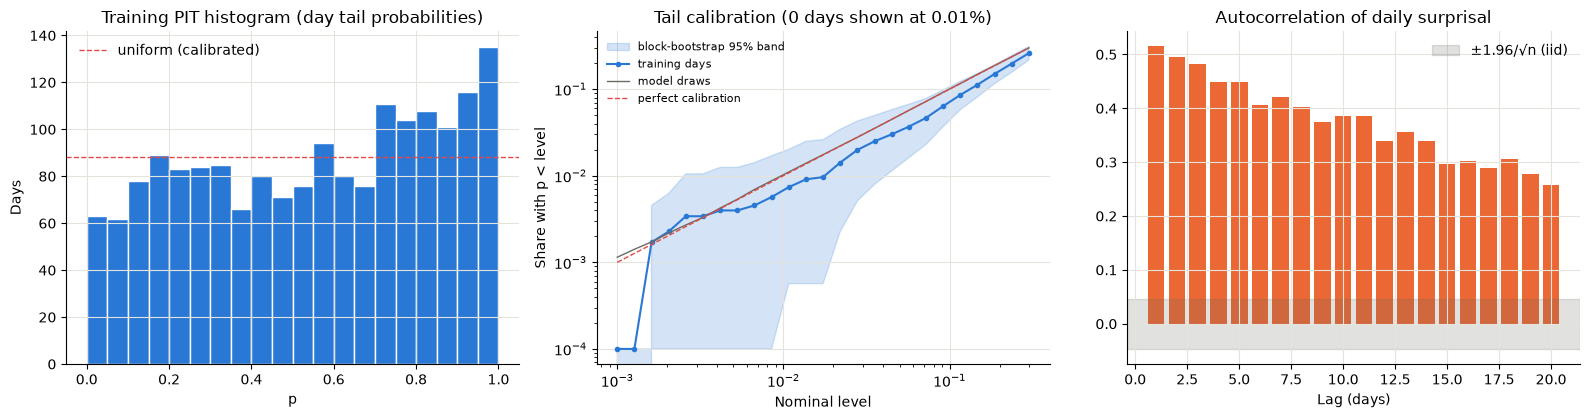

In [9]:
def path_log_tail_probability(surprisals):
    """ln P(Gamma(T,1) >= sum s_t): Fisher score, a monotone transform of S_T (not a calibrated probability)."""
    return 0.0 if len(surprisals) == 0 else float(stats.gamma.logsf(float(np.sum(surprisals)), a=len(surprisals)))

def historical_path_percentile(model, surprisals):
    """Share of actual training windows of the same length whose path is at least as extreme (ties count)."""
    t = len(surprisals)
    if t == 0:
        return 1.0
    ref = np.asarray(model.path_calibration[str(t)])
    return float(np.searchsorted(ref, path_log_tail_probability(surprisals), side="right") / len(ref))

def block_bootstrap(x, stat, n_boot=2000, block=20, seed=SIM["seed"]):
    """Moving-block bootstrap (blocks of `block` consecutive days keep the serial dependence); 95% interval."""
    rng = np.random.default_rng(seed)
    x = np.asarray(x)
    n = len(x)
    out = []
    for _ in range(n_boot):
        starts = rng.integers(0, n - block + 1, size=n // block + 1)
        out.append(stat(x[(starts[:, None] + np.arange(block)).ravel()[:n]]))
    return np.quantile(out, [0.025, 0.975])

LEVELS = (0.05, 0.01, 0.001)
p_train = stats.f.sf(mahalanobis_sq(F, plaus.mu, plaus.sigma) / K, K, plaus.nu)        # training factor days
x_model = sample_mvt(np.random.default_rng(SIM["seed"]), plaus.mu, plaus.sigma, plaus.nu, 200_000)
p_model = stats.f.sf(mahalanobis_sq(x_model, plaus.mu, plaus.sigma) / K, K, plaus.nu)   # draws from the fitted model

# Day-level calibration (original table, kept for comparison with results/stage4).
cal_rows = []
for label, (mu_, sig_, nu_) in {"factor-only t (plausibility)": (plaus.mu, plaus.sigma, plaus.nu),
                                "joint t factor marginal": (joint.mu[:K], joint.sigma[:K, :K], joint.nu)}.items():
    p = stats.f.sf(mahalanobis_sq(F, mu_, sig_) / K, K, nu_)
    cal_rows.append({"model": label, "nu": nu_, **{f"share of train days p<{a:g}": (p < a).mean() for a in LEVELS}})
display(pd.DataFrame(cal_rows).style.hide(axis="index").format("{:.2%}", subset=pd.IndexSlice[:, [c for c in cal_rows[0] if c.startswith("share")]])
        .set_caption("Day-level calibration: nominal 5% / 1% / 0.1%"))

rows = []
for a in LEVELS:
    c = int((p_train < a).sum())
    ci = stats.binomtest(c, len(p_train)).proportion_ci(0.95, method="exact")
    bb = block_bootstrap(p_train, lambda z, a=a: (z < a).mean())
    rows.append({"nominal level": a, "model draws (n=200,000)": (p_model < a).mean(), "training days": c / len(p_train),
                 "count / expected": f"{c} / {a * len(p_train):.1f}", "exact binomial 95% CI (assumes iid)": f"[{ci.low:.2%}, {ci.high:.2%}]",
                 "block-bootstrap 95% CI (dependence-aware)": f"[{bb[0]:.2%}, {bb[1]:.2%}]" if c > 0 else "n/a: 0 events (bootstrap degenerate)",
                 "binomial p-value (iid)": stats.binomtest(c, len(p_train), a).pvalue,
                 "nominal consistent with data": (bb[0] <= a <= bb[1]) if c > 0 else f"{ci.low <= a <= ci.high} (exact binomial; 0 events)"})
calib_detail = pd.DataFrame(rows)
display(calib_detail.style.hide(axis="index").format({"nominal level": "{:.1%}", "model draws (n=200,000)": "{:.3%}", "training days": "{:.2%}",
                                                       "binomial p-value (iid)": "{:.3f}"})
        .set_caption("Factor-only t: tail rates with uncertainty (training days are in-sample)"))
day_s = -stats.f.logsf(mahalanobis_sq(F, plaus.mu, plaus.sigma) / K, K, plaus.nu)
acf = [float(np.corrcoef(day_s[l:], day_s[:-l])[0, 1]) for l in range(1, 21)]
print(f"F transform check: model draws give {', '.join(f'{(p_model < a).mean():.3%}' for a in LEVELS)} vs nominal 5% / 1% / 0.1% -> transform correct.")
print(f"Training PIT: KS p = {stats.kstest(p_train, 'uniform').pvalue:.1e} (iid assumption; dependence makes this optimistic), "
      f"mean surprisal {day_s.mean():.3f} vs 1 under uniformity; lag-1..5 surprisal autocorrelation {np.round(acf[:5], 2).tolist()}.")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
axes[0].hist(p_train, bins=20, range=(0, 1), color="#2a78d6", edgecolor="white")
axes[0].axhline(len(p_train) / 20, color="#e34948", linestyle="--", linewidth=1, label="uniform (calibrated)")
axes[0].set_title("Training PIT histogram (day tail probabilities)"); axes[0].set_xlabel("p"); axes[0].set_ylabel("Days"); axes[0].legend(frameon=False)
grid_levels = np.geomspace(1e-3, 0.3, 25)
obs = np.array([(p_train < a).mean() for a in grid_levels])
band = np.array([block_bootstrap(p_train, lambda z, a=a: (z < a).mean(), n_boot=500) for a in grid_levels])
axes[1].fill_between(grid_levels, np.maximum(band[:, 0], 1e-4), band[:, 1], color="#2a78d6", alpha=0.2, label="block-bootstrap 95% band")
axes[1].plot(grid_levels, np.maximum(obs, 1e-4), color="#2a78d6", marker="o", markersize=3, label="training days")
axes[1].plot(grid_levels, [(p_model < a).mean() for a in grid_levels], color="#6b6a63", linewidth=1, label="model draws")
axes[1].plot(grid_levels, grid_levels, color="#e34948", linestyle="--", linewidth=1, label="perfect calibration")
axes[1].set_xscale("log"); axes[1].set_yscale("log"); axes[1].set_xlabel("Nominal level"); axes[1].set_ylabel("Share with p < level")
axes[1].set_title("Tail calibration (0 days shown at 0.01%)"); axes[1].legend(frameon=False, fontsize=8)
axes[2].bar(range(1, 21), acf, color="#eb6834")
axes[2].axhspan(-1.96 / np.sqrt(len(day_s)), 1.96 / np.sqrt(len(day_s)), color="#6b6a63", alpha=0.2, label="±1.96/√n (iid)")
axes[2].set_title("Autocorrelation of daily surprisal"); axes[2].set_xlabel("Lag (days)"); axes[2].legend(frameon=False)
plt.tight_layout(); plt.show()
compare("plausibility calibration p<5/1/0.1% (factor t)", [cal_rows[0][c] for c in cal_rows[0] if c.startswith("share")],
        [r["empirical_share"] for r in REF_DIAG["calibration_plausibility_model"]["tail_rates"]], 1e-12)

T (days),windows (overlapping),approx. non-overlapping,mean S_T (Gamma: T),var S_T (Gamma: T),Gamma P<1% share,Gamma P<0.1% share,1% threshold on S_T,threshold 95% block-bootstrap
1,1762,1762,0.86,0.83,0.68%,0.00%,3.99,"[3.18, 5.51]"
2,1761,880,1.72,2.51,1.65%,0.68%,7.92,"[5.30, 10.30]"
3,1760,586,2.58,5.02,2.44%,0.97%,11.02,"[7.45, 14.69]"
4,1759,439,3.44,8.33,3.41%,1.48%,14.43,"[9.98, 20.42]"
5,1758,351,4.30,12.39,3.75%,2.05%,17.92,"[11.74, 26.16]"


Rank = empirical share of real windows with S_T >= candidate: verified for T = 1..5.
The most extreme 1% of 5-day training windows (18 windows) end in: {'2020-03': 16, '2020-04': 2} -> the 1% rule is anchored on one episode.
Validation 5-day windows (497): share ranked < 1%: 0.00%, < 5%: 8.85% (a calmer regime than 2020; evaluation only)


,daily SPY,daily QQQ,daily XLF,daily XLE,Mahalanobis^2 (diagnostic),day tail prob p,S_5 = sum of surprisals,real windows with S_5 >= S,percentile rank,plausible (rank >= 1%),decision vs threshold band,Fisher-Gamma score (not a probability),5-day SPY move,daily QQQ-SPY spread,5-day portfolio loss (held 5 days),breaches 10% loss limit
scenario,,,,,,,,,,,,,,,,
zero shock,+0.00%,+0.00%,+0.00%,+0.00%,0.04,9.998e-01,0.00,1758 / 1758,1.0000,True,robust,1.00e+00,+0.00%,+0.00%,-0.10%,False
moderate broad decline (-0.15 all),-1.90%,-2.39%,-2.54%,-3.50%,12.31,1.689e-01,8.89,142 / 1758,0.0808,True,robust,5.87e-02,-9.15%,-0.49%,11.03%,True
severe synchronized decline (-0.5 all),-6.33%,-7.98%,-8.46%,-11.68%,131.61,4.524e-03,26.99,3 / 1758,0.0017,False,robust,4.89e-08,-27.90%,-1.65%,33.18%,True
"opposing factors (SPY -0.2, QQQ +0.2)",-2.53%,+3.19%,+0.00%,+0.00%,485.94,4.814e-04,38.19,0 / 1758,0.0000,False,robust,2.55e-12,-12.04%,+5.73%,0.00%,False


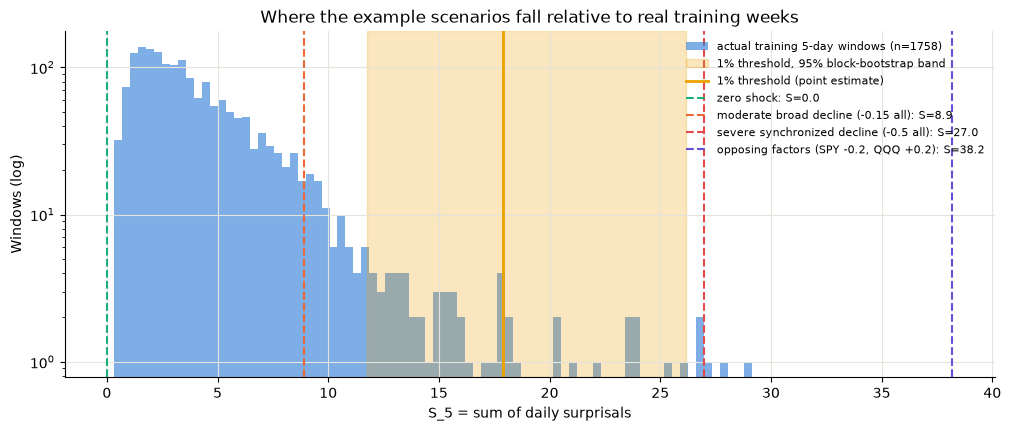

In [10]:
# Path statistic S_T on overlapping training windows, the Gamma assumption, and threshold uncertainty.
q = SIM["min_plausibility"]
path_rows, S_ref = [], {}
for t in range(1, HORIZON + 1):
    S = np.convolve(day_s, np.ones(t), mode="valid")
    S_ref[t] = S
    assert np.allclose(np.sort(stats.gamma.logsf(S, a=t)), path_calibration[str(t)])          # calibration = sorted Fisher scores
    thr = np.quantile(S, 1 - q)
    lo, hi = block_bootstrap(S, lambda z: np.quantile(z, 1 - q))
    path_rows.append({"T (days)": t, "windows (overlapping)": len(S), "approx. non-overlapping": len(S) // t,
                      "mean S_T (Gamma: T)": S.mean(), "var S_T (Gamma: T)": S.var(ddof=1),
                      "Gamma P<1% share": (stats.gamma.sf(S, a=t) < 0.01).mean(), "Gamma P<0.1% share": (stats.gamma.sf(S, a=t) < 0.001).mean(),
                      "1% threshold on S_T": thr, "threshold 95% block-bootstrap": f"[{lo:.2f}, {hi:.2f}]"})
    S_ref[f"band{t}"] = (lo, hi)
display(pd.DataFrame(path_rows).style.hide(axis="index").format({"mean S_T (Gamma: T)": "{:.2f}", "var S_T (Gamma: T)": "{:.2f}",
        "Gamma P<1% share": "{:.2%}", "Gamma P<0.1% share": "{:.2%}", "1% threshold on S_T": "{:.2f}"})
        .set_caption("Gamma(T,1) would need mean = var = T and 1% / 0.1% shares; real windows violate it, the empirical rank does not use it"))

rng_chk = np.random.default_rng(SIM["seed"])
for t in range(1, HORIZON + 1):                        # rank == empirical share of windows with S >= candidate
    for cand in rng_chk.exponential(1.5, size=(30, t)):
        assert math.isclose(historical_path_percentile(model, list(cand)), np.mean(S_ref[t] >= cand.sum() - 1e-9), abs_tol=1e-12)
S5 = S_ref[HORIZON]
top = np.argsort(-S5)[: int(np.ceil(q * len(S5)))]
months = pd.Series(train_f.index[top + HORIZON - 1].strftime("%Y-%m")).value_counts().sort_index()
print(f"Rank = empirical share of real windows with S_T >= candidate: verified for T = 1..{HORIZON}.")
print(f"The most extreme 1% of {HORIZON}-day training windows ({len(top)} windows) end in: {months.to_dict()} -> the 1% rule is anchored on one episode.")

# Out-of-sample evaluation only (validation split; nothing fitted or tuned on it; test split untouched).
Fv = select_window(source[list(FACTORS)], *SPLITS["validation"]).dropna().to_numpy()
sv = -stats.f.logsf(mahalanobis_sq(Fv, plaus.mu, plaus.sigma) / K, K, plaus.nu)
v_ranks = np.array([historical_path_percentile(model, list(sv[i:i + HORIZON])) for i in range(len(sv) - HORIZON + 1)])
print(f"Validation {HORIZON}-day windows ({len(v_ranks)}): share ranked < 1%: {(v_ranks < 0.01).mean():.2%}, < 5%: {(v_ranks < 0.05).mean():.2%} "
      f"(a calmer regime than 2020; evaluation only)")

# Scenarios: plausibility, breach and severity reported separately, with threshold uncertainty.
spy, qqq = FACTORS.index("SPY_return"), FACTORS.index("QQQ_return")
real_spy5 = float((np.exp(np.log1p(train_f["SPY_return"]).rolling(HORIZON).sum()) - 1).min())
real_spread = float((train_f["QQQ_return"] - train_f["SPY_return"]).abs().max())
lo5, hi5 = S_ref[f"band{HORIZON}"]
plaus_scenarios = {
    "zero shock": np.zeros(K),
    "moderate broad decline (-0.15 all)": np.full(K, -0.15),
    "severe synchronized decline (-0.5 all)": np.full(K, -0.5),
    "opposing factors (SPY -0.2, QQQ +0.2)": one_hot(MARKET, -0.2) + one_hot("QQQ_return", 0.2),
}
rows = []
for label, a in plaus_scenarios.items():
    step = simulator.step(a, np.random.default_rng(SIM["seed"]), mode="mean")
    f = step.factor_shock
    s = [step.plausibility.surprisal] * HORIZON
    S = float(np.sum(s))
    pct = historical_path_percentile(model, s)
    r_p = float(step.stock_returns @ WEIGHTS.to_numpy())
    loss5 = 1 - (1 + r_p) ** HORIZON
    rows.append({"scenario": label, **{f"daily {short(n)}": v for n, v in zip(FACTORS, f)},
                 "Mahalanobis^2 (diagnostic)": step.plausibility.mahalanobis_sq, "day tail prob p": step.plausibility.tail_probability,
                 "S_5 = sum of surprisals": S, "real windows with S_5 >= S": f"{int((S5 >= S - 1e-9).sum())} / {len(S5)}",
                 "percentile rank": pct, "plausible (rank >= 1%)": pct >= q,
                 "decision vs threshold band": ("robust" if (S < lo5 or S > hi5) else "UNCERTAIN (inside band)"),
                 "Fisher-Gamma score (not a probability)": math.exp(path_log_tail_probability(s)),
                 "5-day SPY move": (1 + f[spy]) ** HORIZON - 1, "daily QQQ-SPY spread": f[qqq] - f[spy],
                 "5-day portfolio loss (held 5 days)": loss5, "breaches 10% loss limit": loss5 >= 0.10})
plaus_table = pd.DataFrame(rows).set_index("scenario")
display(plaus_table.style.format({**{f"daily {short(n)}": "{:+.2%}" for n in FACTORS}, "Mahalanobis^2 (diagnostic)": "{:.2f}", "day tail prob p": "{:.3e}",
                                  "S_5 = sum of surprisals": "{:.2f}", "percentile rank": "{:.4f}", "Fisher-Gamma score (not a probability)": "{:.2e}",
                                  "5-day SPY move": "{:+.2%}", "daily QQQ-SPY spread": "{:+.2%}", "5-day portfolio loss (held 5 days)": "{:.2%}"})
        .set_caption(f"1% threshold on S_5 = {np.quantile(S5, 1 - q):.2f}, 95% block-bootstrap band [{lo5:.2f}, {hi5:.2f}]. "
                     f"Training comparators: worst real 5-day SPY {real_spy5:+.2%}; largest real |QQQ-SPY| day {real_spread:.2%}."))

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.hist(S5, bins=80, color="#2a78d6", alpha=0.6, label=f"actual training {HORIZON}-day windows (n={len(S5)})")
ax.axvspan(lo5, hi5, color="#eda100", alpha=0.25, label="1% threshold, 95% block-bootstrap band")
ax.axvline(np.quantile(S5, 1 - q), color="#eda100", linewidth=2, label="1% threshold (point estimate)")
for (label, row), col in zip(plaus_table.iterrows(), ["#1baf7a", "#eb6834", "#e34948", "#6250d6"]):
    ax.axvline(row["S_5 = sum of surprisals"], color=col, linestyle="--", linewidth=1.5, label=f"{label}: S={row['S_5 = sum of surprisals']:.1f}")
ax.set_yscale("log"); ax.set_xlabel(f"S_{HORIZON} = sum of daily surprisals"); ax.set_ylabel("Windows (log)")
ax.set_title("Where the example scenarios fall relative to real training weeks")
ax.legend(frameon=False, fontsize=8, loc="upper right")
plt.show()

## 10. Gymnasium environment

In [11]:
def evaluate_path(weights, path_returns, capital):
    """Stage 3 path valuation: constant-mix value path from V0, cumulative loss and max drawdown."""
    r_p = path_returns @ weights
    values = np.concatenate([[capital], capital * np.cumprod(1.0 + r_p)])
    dd = values / np.maximum.accumulate(values) - 1.0
    return {"values": values, "final_value": float(values[-1]), "initial_value": float(values[0]),
            "loss_pct": -(values[-1] / values[0] - 1.0), "max_drawdown": float(min(dd.min(), 0.0))}

def evaluate_path_limits(limits, observations, tol):
    """Each limit against every observation with the same metric, units and horizon; otherwise not evaluated."""
    out = []
    for spec in limits:
        matched = [o for o in observations if o["metric"] == spec["metric"] and o["units"] == spec["units"]
                   and o["horizon_days"] == spec["horizon_days"]]
        if not matched:
            out.append({"limit_name": spec["name"], "status": "not_evaluated", "breached": None, "observed": None, "threshold": spec["threshold"]})
        for o in matched:
            b = o["value"] >= spec["threshold"] - tol if spec["breach_rule"] == ">=" else o["value"] > spec["threshold"] + tol
            out.append({"limit_name": spec["name"], "status": "breach" if b else "within_limit", "breached": b,
                        "observed": o["value"], "threshold": spec["threshold"]})
    return out

def plausibility_log_threshold(model, t, q):
    """L*_t: rank >= q  <=>  path log tail probability >= L*_t (k = ceil(q N) on the sorted training calibration)."""
    ref = model.path_calibration[str(t)]
    return float(ref[max(1, math.ceil(round(q * len(ref), 9))) - 1])

def implausibility_credit_fraction(log_tail, log_threshold):
    """L*/ell in [0, 1] for ell < L*: continuous, rises towards 1 as the path approaches plausibility, -> 0 if extreme."""
    if log_tail >= log_threshold:
        return 1.0
    if not np.isfinite(log_tail) or log_threshold >= 0.0:
        return 0.0
    return float(np.clip(log_threshold / log_tail, 0.0, 1.0))

class StressTestEnv(gym.Env):
    """Agent picks bounded factor shocks for up to `horizon` days, searching for plausible limit breaches."""
    metadata = {"render_modes": []}

    def __init__(self, weights, capital, simulator, limits, env_cfg, sim_cfg, tol, market_states, state_mean, state_sd):
        super().__init__()
        self.weights = weights.to_numpy(dtype=float)
        self.tickers = tuple(weights.index)
        assert tuple(simulator.model.tickers) == self.tickers
        self.capital, self.simulator, self.config, self.sim_config, self.tol = capital, simulator, env_cfg, sim_cfg, tol
        self.horizon = sim_cfg["horizon_days"]
        self.path_limits = [l for l in limits if l["metric"] in PATH_METRICS and l["horizon_days"] == self.horizon]
        if not self.path_limits:
            raise ValueError(f"no cumulative_loss/max_drawdown limit with horizon {self.horizon} days")
        if market_states.empty or market_states.isna().any().any():
            raise ValueError("market_states must be non-empty and complete")
        self.market_states = market_states
        self.state_mean = state_mean[market_states.columns]
        self.state_sd = state_sd[market_states.columns].replace(0, 1.0)
        m = simulator.model
        self.observation_names = (["remaining_fraction"] + [f"cum_{f}" for f in m.factors] + [f"last_{f}" for f in m.factors]
                                  + [f"cum_{t}_return" for t in m.tickers]
                                  + ["value_ratio", "cumulative_loss", "path_drawdown", "last_portfolio_return",
                                     "cumulative_surprisal", "path_log_tail_probability", "path_historical_percentile"]
                                  + [f"state_{c}" for c in market_states.columns])
        self.log_thresholds = {t: plausibility_log_threshold(m, t, sim_cfg["min_plausibility"]) for t in range(1, self.horizon + 1)}
        self.action_space = spaces.Box(-1.0, 1.0, shape=(m.k,), dtype=np.float32)
        self.observation_space = spaces.Box(-np.inf, np.inf, shape=(len(self.observation_names),), dtype=np.float32)
        self._t, self._done = 0, True

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        options = options or {}
        if "anchor_date" in options:
            self.anchor = pd.Timestamp(options["anchor_date"])
            if self.anchor not in self.market_states.index:
                raise ValueError(f"anchor date {self.anchor.date()} not in the anchor window")
        else:
            self.anchor = self.market_states.index[int(self.np_random.integers(len(self.market_states)))]
        self._state = ((self.market_states.loc[self.anchor] - self.state_mean) / self.state_sd).to_numpy()
        self._factor_path = np.zeros((0, self.simulator.model.k))
        self._return_path = np.zeros((0, len(self.tickers)))
        self._surprisals, self._t, self._dd, self._last_rp = [], 0, 0.0, 0.0
        self._result, self._breach_paid, self._implausible_charged, self._done = None, False, False, False
        return self._observation(), {"anchor_date": self.anchor.date().isoformat(), "step": 0}

    def _observation(self):
        k, n = self.simulator.model.k, len(self.tickers)
        cum_f = np.prod(1 + self._factor_path, axis=0) - 1 if len(self._factor_path) else np.zeros(k)
        last_f = self._factor_path[-1] if len(self._factor_path) else np.zeros(k)
        cum_r = np.prod(1 + self._return_path, axis=0) - 1 if len(self._return_path) else np.zeros(n)
        r = self._result
        return np.concatenate([
            [(self.horizon - self._t) / self.horizon], cum_f, last_f, cum_r,
            [r["final_value"] / r["initial_value"] if r else 1.0, r["loss_pct"] if r else 0.0, self._dd, self._last_rp,
             float(np.sum(self._surprisals)), path_log_tail_probability(self._surprisals),
             historical_path_percentile(self.simulator.model, self._surprisals)],
            self._state]).astype(np.float32)

    def _limit_observations(self, result):
        # Path drawdown is checked every step (it can only grow); cumulative loss only at the horizon.
        obs = [{"metric": "max_drawdown", "value": -result["max_drawdown"], "units": RISK_METRIC_UNITS["max_drawdown"], "horizon_days": self.horizon}]
        if self._t == self.horizon:
            obs.append({"metric": "cumulative_loss", "value": result["loss_pct"], "units": RISK_METRIC_UNITS["cumulative_loss"], "horizon_days": self.horizon})
        return obs

    def step(self, action):
        if self._done:
            raise RuntimeError("episode finished; call reset()")
        cfg = self.config
        try:
            sim = self.simulator.step(action, self.np_random)
        except InvalidSimulationError as exc:
            self._done = True
            comps = {"breach": 0.0, "severity": 0.0, "plausibility": 0.0, "magnitude": 0.0,
                     "step": -cfg["step_penalty"], "invalid": -cfg["invalid_penalty"], "plausibility_credit": 0.0}
            return self._observation(), float(sum(comps.values())), True, False, {
                "invalid": True, "error": str(exc), "reward_components": comps, "step": self._t}
        self._t += 1
        self._factor_path = np.vstack([self._factor_path, sim.factor_shock])
        self._return_path = np.vstack([self._return_path, sim.stock_returns])
        self._surprisals.append(sim.plausibility.surprisal)
        result = evaluate_path(self.weights, self._return_path, self.capital)
        self._result = result
        limit_results = evaluate_path_limits(self.path_limits, self._limit_observations(result), self.tol)
        breached = any(r["breached"] for r in limit_results)
        path_log_p = path_log_tail_probability(self._surprisals)
        percentile = historical_path_percentile(self.simulator.model, self._surprisals)
        plausible = percentile >= self.sim_config["min_plausibility"]
        valid_breach = breached and plausible and not self._breach_paid
        implausible_now = breached and not plausible and not self._implausible_charged   # charged once
        new_dd = max(0.0, -result["max_drawdown"])
        comps = {
            "breach": (cfg["breach_reward"] if valid_breach
                       else -cfg.get("implausible_breach_penalty", 0.0) if implausible_now else 0.0),
            "severity": cfg["severity_weight"] * (new_dd - self._dd),
            "plausibility": -cfg["plausibility_penalty"] * min(sim.plausibility.surprisal, self.sim_config["surprisal_cap"]),
            "magnitude": -cfg["magnitude_penalty"] * float(np.mean(sim.action ** 2)),
            "step": -cfg["step_penalty"],
            "invalid": 0.0,
            "plausibility_credit": (cfg.get("implausible_breach_credit", 0.0) * cfg["breach_reward"]
                                    * implausibility_credit_fraction(path_log_p, self.log_thresholds[self._t]) if implausible_now else 0.0),
        }
        self._breach_paid |= valid_breach
        self._implausible_charged |= implausible_now
        self._dd = new_dd
        self._last_rp = result["values"][-1] / result["values"][-2] - 1.0
        terminated = (breached and cfg["terminate_on_breach"]) or self._t >= self.horizon
        self._done = terminated
        info = {"step": self._t, "anchor_date": self.anchor.date().isoformat(), "action": sim.action.tolist(),
                "factor_shock": dict(zip(self.simulator.model.factors, sim.factor_shock.tolist())),
                "stock_returns": dict(zip(self.tickers, sim.stock_returns.tolist())),
                "portfolio_value": result["final_value"], "cumulative_loss": result["loss_pct"], "path_drawdown": new_dd,
                "plausibility": sim.plausibility.__dict__, "path_log_tail_probability": path_log_p,
                "path_historical_percentile": percentile, "breached": breached, "valid_breach": breached and plausible,
                "implausible_breach": breached and not plausible, "invalid": False, "residual_draws": sim.residual_draws,
                "limit_results": limit_results, "reward_components": comps}
        return self._observation(), float(sum(comps.values())), terminated, False, info

def anchor_states(src, columns, start, end):
    states = select_window(src[list(columns)], start, end).dropna()
    return states, states.mean(), states.std(ddof=1)

def make_env(sim_cfg=SIM):
    """Shock model fitted on the fit window; state standardisation on the fit window; anchors from the anchor window."""
    _, mean, sd = anchor_states(source, sim_cfg["state_columns"], *SPLITS[sim_cfg["fit_window"]])
    states, _, _ = anchor_states(source, sim_cfg["state_columns"], *SPLITS[sim_cfg["anchor_window"]])
    return StressTestEnv(WEIGHTS, CAPITAL, ShockSimulator(model, sim_cfg), LIMITS, ENV_CFG, sim_cfg,
                         float(RISK["comparison_tolerance"]), states, mean, sd)

env = make_env()
print("Action space:     ", env.action_space, "->", [short(f) for f in FACTORS])
print("Observation space:", env.observation_space)
print("Path limits:      ", [l["name"] for l in env.path_limits], "| anchors:", len(env.market_states),
      f"dates ({env.market_states.index.min().date()} -> {env.market_states.index.max().date()})")
display(pd.DataFrame({"index": range(len(env.observation_names)), "observation": env.observation_names}).set_index("index").T)
ref_env = json.loads((STAGE4_RESULTS / "validation_episodes.json").read_text())
assert env.observation_names == ref_env["environment"]["observation_names"]
assert len(env.market_states) == ref_env["environment"]["anchors"]["n_dates"]
print("Observation names and anchor count match the existing environment.")

Action space:      Box(-1.0, 1.0, (4,), float32) -> ['SPY', 'QQQ', 'XLF', 'XLE']
Observation space: Box(-inf, inf, (26,), float32)
Path limits:       ['stress_loss_5d', 'stress_drawdown_5d'] | anchors: 1747 dates (2015-01-27 -> 2021-12-31)


index,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25
observation,remaining_fraction,cum_SPY_return,cum_QQQ_return,cum_XLF_return,cum_XLE_return,last_SPY_return,last_QQQ_return,last_XLF_return,last_XLE_return,cum_AAPL_return,cum_MSFT_return,cum_NVDA_return,cum_JPM_return,cum_XOM_return,cum_JNJ_return,cum_WMT_return,cum_CAT_return,value_ratio,cumulative_loss,path_drawdown,last_portfolio_return,cumulative_surprisal,path_log_tail_probability,path_historical_percentile,state_VIX_close,state_SPY_vol_ann_20d


Observation names and anchor count match the existing environment.


## 11. Run scripted episodes
The existing project scripts (`shock_report.scripted_episodes`): constant daily action, residual mode `mean` (deterministic), anchor = middle training anchor date, seed = `simulation.seed`.

In [12]:
script_env = make_env({**SIM, "residual_mode": "mean"})
ANCHOR = script_env.market_states.index[len(script_env.market_states) // 2].date().isoformat()
SCRIPTS = {
    "zero_shock": np.zeros(K),
    "broad_crash_moderate (-0.15 all factors)": np.full(K, -0.15),
    "broad_crash_severe (-0.5 all factors)": np.full(K, -0.5),
    "market_only (-0.3 SPY)": one_hot(MARKET, -0.3),
    "financials_only (-0.3 XLF)": one_hot("XLF_return", -0.3),
    "incoherent (SPY -0.2, QQQ +0.2)": one_hot(MARKET, -0.2) + one_hot("QQQ_return", 0.2),
}
step_rows, stock_rows, episodes = [], [], []
for name, action in SCRIPTS.items():
    script_env.reset(seed=SIM["seed"], options={"anchor_date": ANCHOR})
    total, comps = 0.0, {}
    for _ in range(script_env.horizon):
        _, r, term, trunc, info = script_env.step(action.astype(np.float32))
        total += r
        for key, v in info["reward_components"].items():
            comps[key] = comps.get(key, 0.0) + v
        reason = ("" if not term else "invalid simulation" if info["invalid"] else
                  ("limit breach (valid)" if info["valid_breach"] else "limit breach (implausible)") if info["breached"] else "horizon reached")
        step_rows.append({"scenario": name, "day": info["step"], **{f"a_{short(f)}": v for f, v in zip(FACTORS, info["action"])},
                          **{f"f_{short(f)}": v for f, v in info["factor_shock"].items()},
                          "portfolio_value": info["portfolio_value"], "cum_loss": info["cumulative_loss"], "drawdown": info["path_drawdown"],
                          **{f"rw_{k}": v for k, v in info["reward_components"].items()}, "reward": r,
                          "breached": info["breached"], "path_percentile": info["path_historical_percentile"],
                          "plausible": info["path_historical_percentile"] >= SIM["min_plausibility"], "termination": reason})
        stock_rows.append({"scenario": name, "day": info["step"], **info["stock_returns"]})
        if term:
            break
    episodes.append({"episode": name, "steps": info["step"], "cumulative_loss": info["cumulative_loss"], "path_drawdown": info["path_drawdown"],
                     "breached": info["breached"], "valid_breach": info["valid_breach"], "path_historical_percentile": info["path_historical_percentile"],
                     "total_reward": total, "termination": reason, "reward_components": comps})

steps_df = pd.DataFrame(step_rows)
stocks_df = pd.DataFrame(stock_rows)
pct_cols = [c for c in steps_df if c.startswith(("f_", ))] + ["cum_loss", "drawdown"]
fmt = {**{c: "{:+.2%}" for c in pct_cols}, **{c: "{:+.3f}" for c in steps_df if c.startswith(("a_", "rw_"))},
       "reward": "{:+.3f}", "portfolio_value": "{:,.2f}", "path_percentile": "{:.4f}"}
print(f"Anchor date: {ANCHOR} | capital {CAPITAL:,.0f} | limits: 5-day loss >= 10% (checked at day 5), 5-day drawdown >= 10% (checked daily)")
for name in SCRIPTS:
    print(f"\n=== {name} ===")
    display(steps_df[steps_df.scenario == name].drop(columns="scenario").style.hide(axis="index").format(fmt))
    display(stocks_df[stocks_df.scenario == name].drop(columns="scenario").style.hide(axis="index").format("{:+.2%}", subset=list(TICKERS))
            .set_caption("Daily simulated stock returns"))

episodes_df = pd.DataFrame(episodes).drop(columns="reward_components").set_index("episode")
display(episodes_df.style.format({"cumulative_loss": "{:.2%}", "path_drawdown": "{:.2%}", "path_historical_percentile": "{:.4f}", "total_reward": "{:.3f}"}))

ref_eps = {e["episode"]: e for e in ref_env["scripted_episodes"]}
assert ref_eps and set(ref_eps) == set(SCRIPTS) and all(e["anchor_date"] == ANCHOR for e in ref_eps.values())
keys = ["steps", "cumulative_loss", "path_drawdown", "path_historical_percentile", "total_reward"]
compare("scripted episodes: steps, loss, DD, percentile, reward",
        [e[k] for e in episodes for k in keys], [ref_eps[e["episode"]][k] for e in episodes for k in keys], 1e-9)
compare("scripted episodes: breach / valid flags", [[e["breached"], e["valid_breach"]] for e in episodes],
        [[ref_eps[e["episode"]]["breached"], ref_eps[e["episode"]]["valid_breach"]] for e in episodes], 0)

Anchor date: 2018-07-16 | capital 100,000 | limits: 5-day loss >= 10% (checked at day 5), 5-day drawdown >= 10% (checked daily)

=== zero_shock ===


day,a_SPY,a_QQQ,a_XLF,a_XLE,f_SPY,f_QQQ,f_XLF,f_XLE,portfolio_value,cum_loss,drawdown,rw_breach,rw_severity,rw_plausibility,rw_magnitude,rw_step,rw_invalid,rw_plausibility_credit,reward,breached,path_percentile,plausible,termination
1,+0.000,+0.000,+0.000,+0.000,+0.00%,+0.00%,+0.00%,+0.00%,"100,019.06",-0.02%,+0.00%,+0.000,+0.000,-0.000,-0.000,-0.010,+0.000,+0.000,-0.010,False,1.0000,True,
2,+0.000,+0.000,+0.000,+0.000,+0.00%,+0.00%,+0.00%,+0.00%,"100,038.12",-0.04%,+0.00%,+0.000,+0.000,-0.000,-0.000,-0.010,+0.000,+0.000,-0.010,False,1.0000,True,
3,+0.000,+0.000,+0.000,+0.000,+0.00%,+0.00%,+0.00%,+0.00%,"100,057.19",-0.06%,+0.00%,+0.000,+0.000,-0.000,-0.000,-0.010,+0.000,+0.000,-0.010,False,1.0000,True,
4,+0.000,+0.000,+0.000,+0.000,+0.00%,+0.00%,+0.00%,+0.00%,"100,076.26",-0.08%,+0.00%,+0.000,+0.000,-0.000,-0.000,-0.010,+0.000,+0.000,-0.010,False,1.0000,True,
5,+0.000,+0.000,+0.000,+0.000,+0.00%,+0.00%,+0.00%,+0.00%,"100,095.34",-0.10%,+0.00%,+0.000,+0.000,-0.000,-0.000,-0.010,+0.000,+0.000,-0.010,False,1.0000,True,horizon reached


day,AAPL,MSFT,NVDA,JPM,XOM,JNJ,WMT,CAT
1,+0.02%,+0.02%,+0.09%,+0.01%,-0.02%,+0.01%,+0.01%,+0.01%
2,+0.02%,+0.02%,+0.09%,+0.01%,-0.02%,+0.01%,+0.01%,+0.01%
3,+0.02%,+0.02%,+0.09%,+0.01%,-0.02%,+0.01%,+0.01%,+0.01%
4,+0.02%,+0.02%,+0.09%,+0.01%,-0.02%,+0.01%,+0.01%,+0.01%
5,+0.02%,+0.02%,+0.09%,+0.01%,-0.02%,+0.01%,+0.01%,+0.01%



=== broad_crash_moderate (-0.15 all factors) ===


day,a_SPY,a_QQQ,a_XLF,a_XLE,f_SPY,f_QQQ,f_XLF,f_XLE,portfolio_value,cum_loss,drawdown,rw_breach,rw_severity,rw_plausibility,rw_magnitude,rw_step,rw_invalid,rw_plausibility_credit,reward,breached,path_percentile,plausible,termination
1,-0.150,-0.150,-0.150,-0.150,-1.90%,-2.39%,-2.54%,-3.50%,"97,688.98",+2.31%,+2.31%,+0.000,+0.116,-0.356,-0.011,-0.010,+0.000,+0.000,-0.261,False,0.1322,True,
2,-0.150,-0.150,-0.150,-0.150,-1.90%,-2.39%,-2.54%,-3.50%,"95,431.38",+4.57%,+4.57%,+0.000,+0.113,-0.356,-0.011,-0.010,+0.000,+0.000,-0.264,False,0.1051,True,
3,-0.150,-0.150,-0.150,-0.150,-1.90%,-2.39%,-2.54%,-3.50%,"93,225.94",+6.77%,+6.77%,+0.000,+0.110,-0.356,-0.011,-0.010,+0.000,+0.000,-0.267,False,0.0938,True,
4,-0.150,-0.150,-0.150,-0.150,-1.90%,-2.39%,-2.54%,-3.50%,"91,071.48",+8.93%,+8.93%,+0.000,+0.108,-0.356,-0.011,-0.010,+0.000,+0.000,-0.269,False,0.0853,True,
5,-0.150,-0.150,-0.150,-0.150,-1.90%,-2.39%,-2.54%,-3.50%,"88,966.80",+11.03%,+11.03%,+10.000,+0.105,-0.356,-0.011,-0.010,+0.000,+0.000,+9.728,True,0.0808,True,limit breach (valid)


...

day,AAPL,MSFT,NVDA,JPM,XOM,JNJ,WMT,CAT
1,+0.17%,+0.30%,-0.69%,-6.85%,+0.04%,+1.81%,+1.47%,-1.23%
2,+0.17%,+0.30%,-0.69%,-6.85%,+0.04%,+1.81%,+1.47%,-1.23%
3,+0.17%,+0.30%,-0.69%,-6.85%,+0.04%,+1.81%,+1.47%,-1.23%
4,+0.17%,+0.30%,-0.69%,-6.85%,+0.04%,+1.81%,+1.47%,-1.23%
5,+0.17%,+0.30%,-0.69%,-6.85%,+0.04%,+1.81%,+1.47%,-1.23%



=== incoherent (SPY -0.2, QQQ +0.2) ===


day,a_SPY,a_QQQ,a_XLF,a_XLE,f_SPY,f_QQQ,f_XLF,f_XLE,portfolio_value,cum_loss,drawdown,rw_breach,rw_severity,rw_plausibility,rw_magnitude,rw_step,rw_invalid,rw_plausibility_credit,reward,breached,path_percentile,plausible,termination
1,-0.200,+0.200,+0.000,+0.000,-2.53%,+3.19%,+0.00%,+0.00%,"99,999.36",+0.00%,+0.00%,+0.000,+0.000,-1.528,-0.010,-0.010,+0.000,+0.000,-1.548,False,0.0000,False,
2,-0.200,+0.200,+0.000,+0.000,-2.53%,+3.19%,+0.00%,+0.00%,"99,998.72",+0.00%,+0.00%,+0.000,+0.000,-1.528,-0.010,-0.010,+0.000,+0.000,-1.548,False,0.0000,False,
3,-0.200,+0.200,+0.000,+0.000,-2.53%,+3.19%,+0.00%,+0.00%,"99,998.09",+0.00%,+0.00%,+0.000,+0.000,-1.528,-0.010,-0.010,+0.000,+0.000,-1.548,False,0.0000,False,
4,-0.200,+0.200,+0.000,+0.000,-2.53%,+3.19%,+0.00%,+0.00%,"99,997.45",+0.00%,+0.00%,+0.000,+0.000,-1.528,-0.010,-0.010,+0.000,+0.000,-1.548,False,0.0000,False,
5,-0.200,+0.200,+0.000,+0.000,-2.53%,+3.19%,+0.00%,+0.00%,"99,996.81",+0.00%,+0.00%,+0.000,+0.000,-1.528,-0.010,-0.010,+0.000,+0.000,-1.548,False,0.0000,False,horizon reached


day,AAPL,MSFT,NVDA,JPM,XOM,JNJ,WMT,CAT
1,+4.90%,+2.71%,+9.84%,+2.24%,-1.64%,-8.24%,-6.29%,-3.52%
2,+4.90%,+2.71%,+9.84%,+2.24%,-1.64%,-8.24%,-6.29%,-3.52%
3,+4.90%,+2.71%,+9.84%,+2.24%,-1.64%,-8.24%,-6.29%,-3.52%
4,+4.90%,+2.71%,+9.84%,+2.24%,-1.64%,-8.24%,-6.29%,-3.52%
5,+4.90%,+2.71%,+9.84%,+2.24%,-1.64%,-8.24%,-6.29%,-3.52%


,steps,cumulative_loss,path_drawdown,breached,valid_breach,path_historical_percentile,total_reward,termination
episode,,,,,,,,
zero_shock,5,-0.10%,0.00%,False,False,1.0000,-0.050,horizon reached
broad_crash_moderate (-0.15 all factors),5,11.03%,11.03%,True,True,0.0808,8.667,limit breach (valid)
broad_crash_severe (-0.5 all factors),2,14.90%,14.90%,True,False,0.0017,-1.685,limit breach (implausible)
market_only (-0.3 SPY),5,7.92%,7.92%,False,False,0.0000,-6.987,horizon reached
financials_only (-0.3 XLF),5,3.08%,3.08%,False,False,0.0040,-5.019,horizon reached
"incoherent (SPY -0.2, QQQ +0.2)",5,0.00%,0.00%,False,False,0.0000,-7.739,horizon reached


## 12. Stress scenario charts

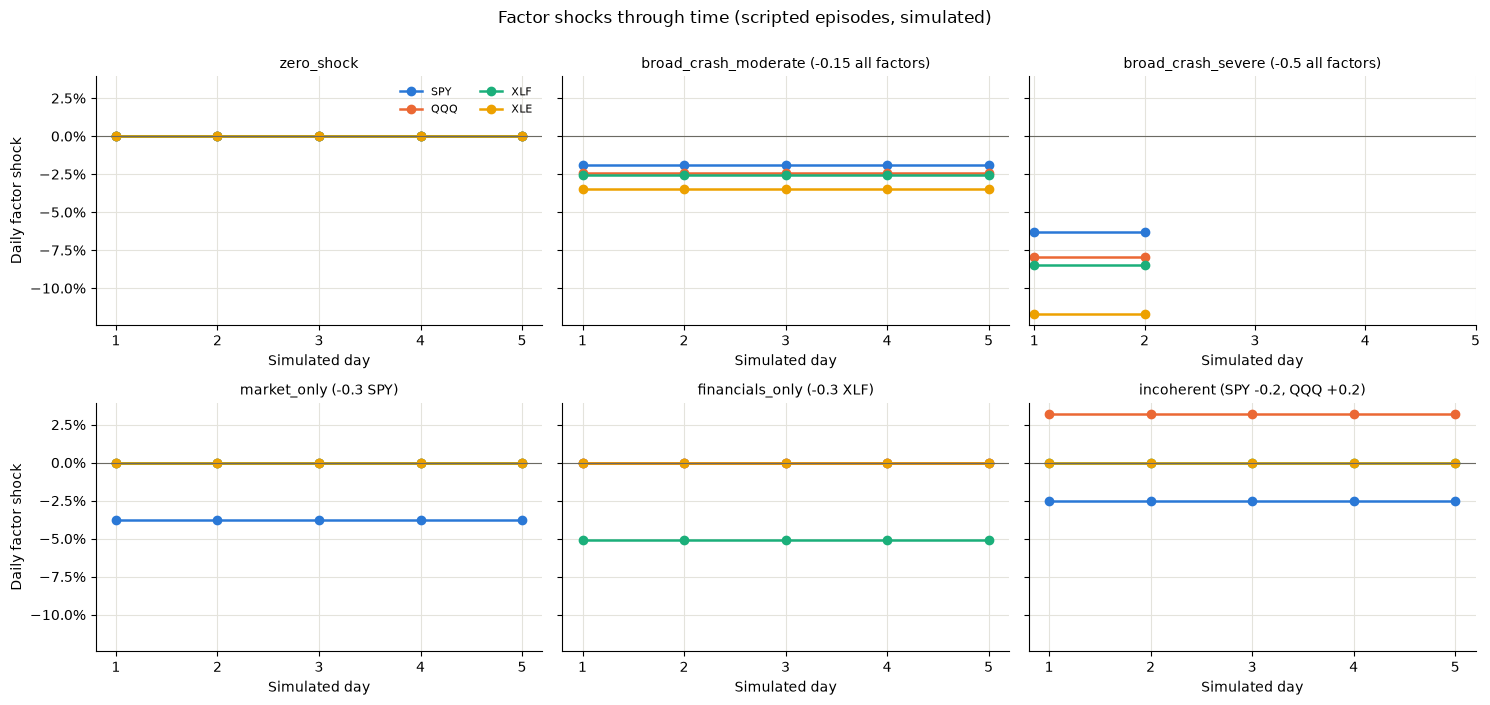

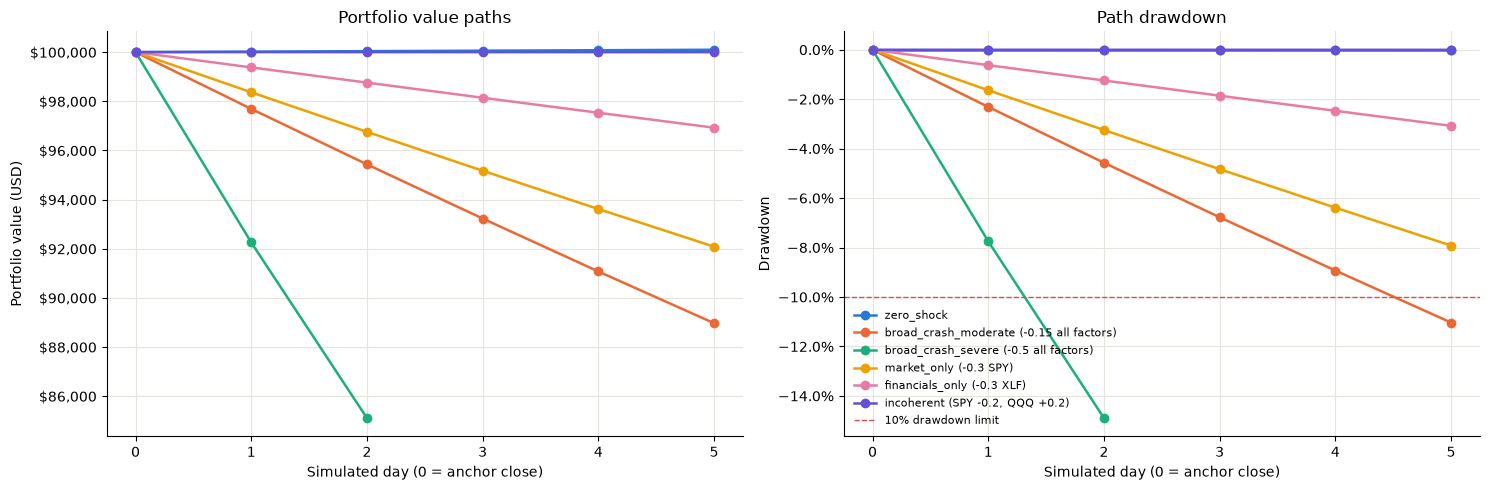

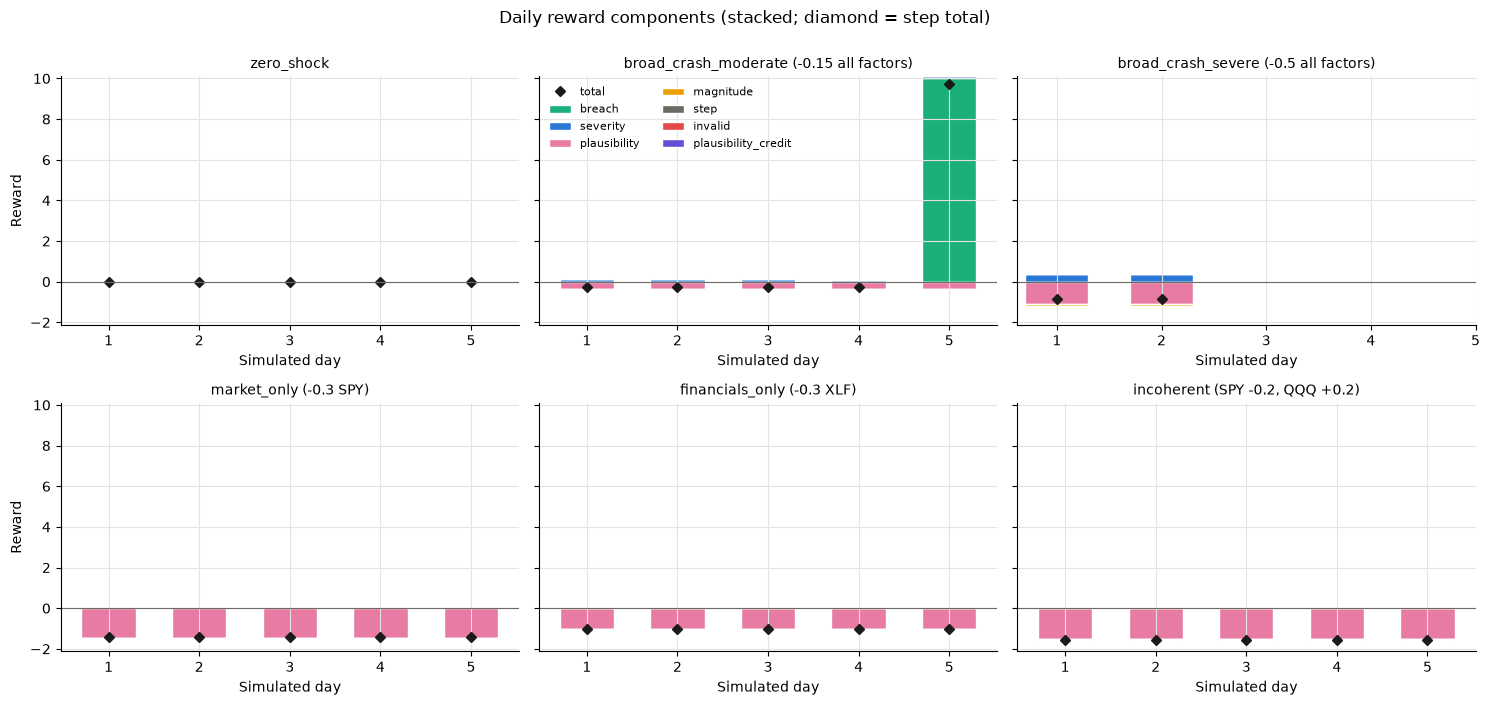

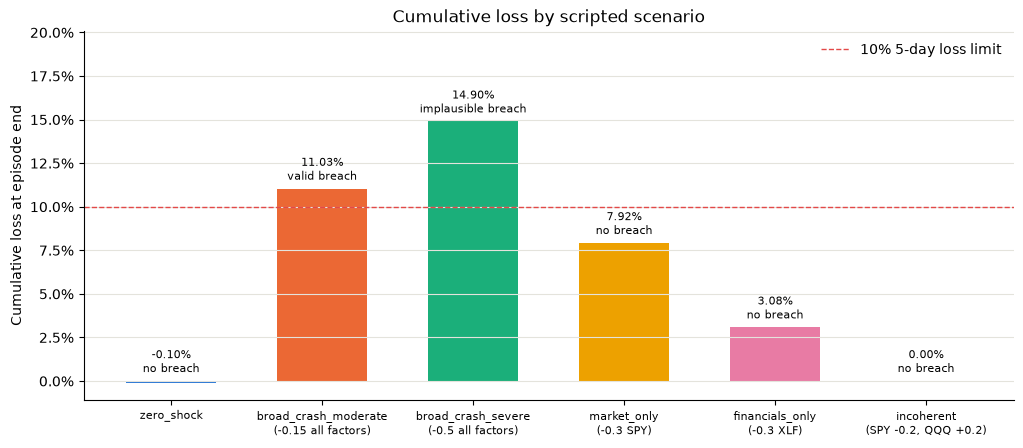

In [13]:
from matplotlib.ticker import PercentFormatter
SC_COLORS = dict(zip(SCRIPTS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]))
F_COLORS = dict(zip([short(f) for f in FACTORS], ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
COMP_COLORS = {"breach": "#1baf7a", "severity": "#2a78d6", "plausibility": "#e87ba4", "magnitude": "#eda100", "step": "#6b6a63", "invalid": "#e34948", "plausibility_credit": "#6250d6"}

fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey=True)
for ax, name in zip(axes.flat, SCRIPTS):
    d = steps_df[steps_df.scenario == name]
    for f in FACTORS:
        ax.plot(d["day"], d[f"f_{short(f)}"] * 100, marker="o", color=F_COLORS[short(f)], label=short(f), linewidth=1.8)
    ax.axhline(0, color="#6b6a63", linewidth=0.8)
    ax.set_title(name, fontsize=10); ax.set_xlabel("Simulated day"); ax.set_xticks(range(1, HORIZON + 1))
    ax.yaxis.set_major_formatter(PercentFormatter())
for ax in axes[:, 0]:
    ax.set_ylabel("Daily factor shock")
axes.flat[0].legend(frameon=False, fontsize=8, ncol=2)
fig.suptitle("Factor shocks through time (scripted episodes, simulated)", y=1.0); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for name in SCRIPTS:
    d = steps_df[steps_df.scenario == name]
    days = [0, *d["day"]]
    values = [CAPITAL, *d["portfolio_value"]]
    axes[0].plot(days, values, marker="o", color=SC_COLORS[name], label=name, linewidth=1.8)
    axes[1].plot(days, [0, *(-d["drawdown"] * 100)], marker="o", color=SC_COLORS[name], label=name, linewidth=1.8)
axes[0].set_title("Portfolio value paths"); axes[0].set_ylabel("Portfolio value (USD)")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
axes[1].axhline(-10, color="#e34948", linestyle="--", linewidth=1, label="10% drawdown limit")
axes[1].set_title("Path drawdown"); axes[1].set_ylabel("Drawdown"); axes[1].yaxis.set_major_formatter(PercentFormatter())
for ax in axes:
    ax.set_xlabel("Simulated day (0 = anchor close)"); ax.set_xticks(range(0, HORIZON + 1))
axes[1].legend(frameon=False, fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey=True)
comp_names = list(COMP_COLORS)
for ax, name in zip(axes.flat, SCRIPTS):
    d = steps_df[steps_df.scenario == name]
    pos, neg = np.zeros(len(d)), np.zeros(len(d))
    for c in comp_names:
        v = d[f"rw_{c}"].to_numpy()
        base = np.where(v >= 0, pos, neg)
        ax.bar(d["day"], v, bottom=base, color=COMP_COLORS[c], label=c, width=0.6, edgecolor="white", linewidth=1)
        pos, neg = pos + np.clip(v, 0, None), neg + np.clip(v, None, 0)
    ax.plot(d["day"], d["reward"], color="#1a1a19", marker="D", markersize=5, linewidth=0, label="total")
    ax.axhline(0, color="#6b6a63", linewidth=0.8)
    ax.set_title(name, fontsize=10); ax.set_xlabel("Simulated day"); ax.set_xticks(range(1, HORIZON + 1))
for ax in axes[:, 0]:
    ax.set_ylabel("Reward")
axes.flat[1].legend(frameon=False, fontsize=8, ncol=2)
fig.suptitle("Daily reward components (stacked; diamond = step total)", y=1.0); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(12, 4.8))
labels = list(SCRIPTS)
vals = [episodes_df.loc[n, "cumulative_loss"] * 100 for n in labels]
bars = ax.bar(range(len(labels)), vals, color=[SC_COLORS[n] for n in labels], width=0.6)
for x, (v, n) in enumerate(zip(vals, labels)):
    status = "valid breach" if episodes_df.loc[n, "valid_breach"] else ("implausible breach" if episodes_df.loc[n, "breached"] else "no breach")
    ax.text(x, max(v, 0) + 0.3, f"{v:.2f}%\n{status}", ha="center", va="bottom", fontsize=8)
ax.axhline(10, color="#e34948", linestyle="--", linewidth=1, label="10% 5-day loss limit")
ax.set_xticks(range(len(labels)), [n.replace(" (", "\n(") for n in labels], fontsize=8)
ax.set_ylabel("Cumulative loss at episode end"); ax.yaxis.set_major_formatter(PercentFormatter())
ax.set_ylim(min(0, min(vals)) - 1, max(vals) * 1.35)
ax.set_title("Cumulative loss by scripted scenario"); ax.legend(frameon=False); ax.grid(axis="x", visible=False)
plt.show()

## 13. Environment validation

In [14]:
results = []
def check(name, fn):
    try:
        ok, detail = fn()
    except Exception as exc:
        ok, detail = False, f"{type(exc).__name__}: {exc}"
    results.append({"check": name, "result": "PASS" if ok else "FAIL", "detail": detail})

def run_check_env():
    e = make_env()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        check_env(e, skip_render_check=True)
    msgs = sorted({re.sub(r"\x1b\[[0-9;]*m", "", str(w.message)).strip() for w in caught})
    return True, f"no errors; {len(msgs)} warning(s)" + (f": {msgs}" if msgs else "")
check("gymnasium check_env", run_check_env)

def spaces_ok():
    e = make_env()
    a = e.action_space
    ok = a.shape == (K,) and np.all(a.low == -1) and np.all(a.high == 1) and e.observation_space.shape == (26,)
    obs, _ = e.reset(seed=0)
    ok &= e.observation_space.contains(obs)
    for _ in range(HORIZON):
        obs, r, term, trunc, info = e.step(e.action_space.sample())
        ok &= e.observation_space.contains(obs) and obs.dtype == np.float32
        if term:
            break
    return ok, f"action {a}, observation {e.observation_space.shape}"
check("observation/action space compliance", spaces_ok)

def reset_step_types():
    e = make_env()
    out = e.reset(seed=1)
    ok = isinstance(out, tuple) and len(out) == 2 and isinstance(out[1], dict)
    s = e.step(np.zeros(K, dtype=np.float32))
    ok &= len(s) == 5 and isinstance(s[1], float) and isinstance(s[2], bool) and s[3] is False and isinstance(s[4], dict)
    return ok, "reset -> (obs, info); step -> (obs, float, bool, False, dict)"
check("valid reset/step outputs", reset_step_types)

def reproducible():
    traces = []
    for _ in range(2):
        e = make_env()
        e.action_space.seed(123)
        rec = []
        for ep in range(5):
            obs, _ = e.reset(seed=500 + ep)
            rec.append(obs)
            done = False
            while not done:
                obs, r, done, _, _ = e.step(e.action_space.sample())
                rec.append(np.r_[obs, r])
        traces.append(np.concatenate(rec))
    return bool(np.array_equal(traces[0], traces[1])), "5 episodes, sampled residuals, identical seeds -> identical trajectories"
check("reproducibility with identical seeds", reproducible)

def breach_termination():
    e = make_env({**SIM, "residual_mode": "mean"})
    e.reset(seed=SIM["seed"], options={"anchor_date": ANCHOR})
    for d in range(1, HORIZON + 1):
        _, _, term, _, info = e.step(np.full(K, -0.5, dtype=np.float32))
        dd_limit = next(l for l in info["limit_results"] if l["limit_name"] == "stress_drawdown_5d")
        if term:
            break
    return (term and d < HORIZON and info["breached"] and dd_limit["breached"] and info["path_drawdown"] >= 0.10,
            f"terminated on day {d}, drawdown {info['path_drawdown']:.2%} >= 10%")
check("termination on configured 5-day drawdown breach", breach_termination)

def implausible_breach():
    e = episodes_df.loc["broad_crash_severe (-0.5 all factors)"]
    m = episodes_df.loc["broad_crash_moderate (-0.15 all factors)"]
    severe_rw = steps_df[steps_df.scenario == "broad_crash_severe (-0.5 all factors)"]["rw_breach"].sum()
    penalty = ENV_CFG.get("implausible_breach_penalty", 0.0)
    ok = (e.breached and not e.valid_breach and e.path_historical_percentile < SIM["min_plausibility"] and severe_rw == -penalty
          and m.breached and m.valid_breach and steps_df[steps_df.scenario == "broad_crash_moderate (-0.15 all factors)"]["rw_breach"].sum() == ENV_CFG["breach_reward"])
    return ok, (f"severe: percentile {e.path_historical_percentile:.4f} < 1% -> no breach reward, implausible-breach penalty -{penalty:g}; "
                f"moderate: {m.path_historical_percentile:.4f} -> +{ENV_CFG['breach_reward']}")
check("implausible breach ends episode without breach reward (penalised if configured)", implausible_breach)

def reward_sum():
    e = make_env()
    e.action_space.seed(7)
    worst = 0.0
    for ep in range(30):
        e.reset(seed=ep)
        done = False
        while not done:
            _, r, done, _, info = e.step(e.action_space.sample())
            worst = max(worst, abs(r - sum(info["reward_components"].values())))
    return worst < 1e-12, f"max |reward - sum(components)| = {worst:.1e} over 30 random episodes"
check("reward = sum of components", reward_sum)

def valid_returns():
    e = make_env()
    e.action_space.seed(11)
    rets, draws = [], []
    for ep in range(100):
        e.reset(seed=1000 + ep)
        done = False
        while not done:
            _, _, done, _, info = e.step(np.sign(e.action_space.sample()).astype(np.float32))  # extreme |a| = 1 corners
            if not info["invalid"]:
                rets.append(list(info["stock_returns"].values())); draws.append(info["residual_draws"])
    rets = np.array(rets)
    ok = bool(np.all(rets > -1) and np.all(np.abs(rets) <= SIM["max_abs_stock_return"]))
    raised = 0
    for bad in [np.full(K, 1.5), np.zeros(K + 1), np.full(K, np.nan)]:
        try:
            simulator.validate_action(bad)
        except InvalidActionError:
            raised += 1
    return ok and raised == 3, f"{len(rets)} extreme-corner steps: all |r| <= {SIM['max_abs_stock_return']:.0%}, max residual redraws {max(draws)}; 3/3 invalid actions rejected"
check("valid-return handling and action validation", valid_returns)

def training_only():
    perturbed = source.copy()
    held_out = perturbed.index > pd.Timestamp(FIT_END)
    perturbed.loc[held_out, [*FACTORS, *STOCK_COLS]] = perturbed.loc[held_out, [*FACTORS, *STOCK_COLS]] * -3.0
    f2, r2_, _ = training_matrix(perturbed, TICKERS, FACTORS, FIT_START, FIT_END)
    same = f2.equals(train_f) and r2_.equals(train_r)
    return same and train_f.index.max() <= pd.Timestamp(FIT_END), \
        f"fit rows {train_f.index.min().date()}..{train_f.index.max().date()}; changing all validation/test returns leaves the fit input unchanged"
check("training-only model fitting", training_only)

def random_baseline():
    e = make_env()
    eps, seed = 200, SIM["seed"]
    e.action_space.seed(seed)
    breaches = valid = 0
    rewards = []
    for ep in range(eps):
        e.reset(seed=seed + ep)
        done, total = False, 0.0
        while not done:
            _, r, done, _, info = e.step(e.action_space.sample())
            total += r
        breaches += bool(info.get("breached")); valid += bool(info.get("valid_breach")); rewards.append(total)
    ref = ref_env["random_policy_baseline"]
    compare("random-policy baseline (200 episodes): breach rate, valid rate, mean reward",
            [breaches / eps, valid / eps, np.mean(rewards)], [ref["breach_rate"], ref["valid_breach_rate"], ref["mean_reward"]], 1e-9)
    return COMPARE[-1]["match"], f"breach {breaches / eps:.1%}, valid {valid / eps:.1%}, mean reward {np.mean(rewards):.4f} (existing: {ref['breach_rate']:.1%}, {ref['valid_breach_rate']:.1%}, {ref['mean_reward']:.4f})"
check("random-policy baseline reproduces existing run", random_baseline)

# Existing Stage 4 unit tests (run as a separate process; the notebook itself imports no project code).
proc = subprocess.run([sys.executable, "-m", "pytest", "tests/test_shocks.py", "tests/test_env.py", "-q", "--color=no", "-p", "no:cacheprovider"],
                      cwd=PROJECT_ROOT, capture_output=True, text=True)
pytest_summary = (proc.stdout.strip().splitlines() or ["no output"])[-1]
results.append({"check": "existing tests: tests/test_shocks.py + tests/test_env.py", "result": "PASS" if proc.returncode == 0 else "FAIL",
                "detail": pytest_summary})

def graded_credit():
    """kappa = 0.5 test instance (config default stays 0): gate equivalence, monotone/bounded credit, valid dominance."""
    rng = np.random.default_rng(SIM["seed"])
    gate_ok = all((historical_path_percentile(model, s) >= SIM["min_plausibility"])
                  == (path_log_tail_probability(s) >= plausibility_log_threshold(model, len(s), SIM["min_plausibility"]))
                  for s in (list(rng.exponential(rng.uniform(0.3, 4.0), int(rng.integers(1, HORIZON + 1)))) for _ in range(2000)))
    kappa = 0.5
    e = StressTestEnv(WEIGHTS, CAPITAL, ShockSimulator(model, {**SIM, "residual_mode": "mean"}), LIMITS,
                      {**ENV_CFG, "implausible_breach_credit": kappa}, {**SIM, "residual_mode": "mean"},
                      float(RISK["comparison_tolerance"]), *anchor_states(source, SIM["state_columns"], *SPLITS["train"]),
                      )
    imp, val = [], []
    for c in np.arange(1.0, 0.0, -0.05):
        e.reset(seed=SIM["seed"], options={"anchor_date": ANCHOR})
        tot, credit = 0.0, 0.0
        for d in range(HORIZON):
            _, r, term, _, info = e.step(np.full(K, -c if d == 0 else -0.15, dtype=np.float32))
            tot += r; credit += info["reward_components"]["plausibility_credit"]
            if term:
                break
        (imp if info["implausible_breach"] else val if info["valid_breach"] else []).append((c, credit, tot))
    credits = [x[1] for x in imp]
    ok = (gate_ok and len(imp) >= 3 and len(val) >= 3 and all(0 < x <= kappa * ENV_CFG["breach_reward"] for x in credits)
          and all(a <= b + 1e-12 for a, b in zip(credits, credits[1:])) and min(v[2] for v in val) > max(x[2] for x in imp)
          and all(v[1] == 0 for v in val))
    return ok, (f"kappa=0.5: implausible-crash credit {min(credits):.2f}->{max(credits):.2f} as crashes get milder, returns ≤ {max(x[2] for x in imp):+.2f}; "
                f"valid returns ≥ {min(v[2] for v in val):+.2f}; gate ⇔ (log tail ≥ L*_t) on 2,000 paths; config default kappa = {ENV_CFG.get('implausible_breach_credit', 0.0)}")
check("graded plausibility credit (opt-in): bounded, monotone, valid dominates", graded_credit)

env_validation = pd.DataFrame(results)
display(env_validation.style.hide(axis="index").map(
    lambda v: "color: #008300; font-weight: bold" if v == "PASS" else ("color: #e34948; font-weight: bold" if v == "FAIL" else ""), subset=["result"]))
for r in results:
    print(f"{r['result']}  {r['check']}")

check,result,detail
gymnasium check_env,PASS,"no errors; 2 warning(s): ['WARN: A Box observation space maximum value is infinity. This is probably too high.', 'WARN: A Box observation space minimum value is -infinity. This is probably too low.']"
observation/action space compliance,PASS,"action Box(-1.0, 1.0, (4,), float32), observation (26,)"
valid reset/step outputs,PASS,"reset -> (obs, info); step -> (obs, float, bool, False, dict)"
reproducibility with identical seeds,PASS,"5 episodes, sampled residuals, identical seeds -> identical trajectories"
termination on configured 5-day drawdown breach,PASS,"terminated on day 2, drawdown 14.90% >= 10%"
implausible breach ends episode without breach reward (penalised if configured),PASS,"severe: percentile 0.0017 < 1% -> no breach reward, implausible-breach penalty -0; moderate: 0.0808 -> +10.0"
reward = sum of components,PASS,max |reward - sum(components)| = 0.0e+00 over 30 random episodes
valid-return handling and action validation,PASS,"292 extreme-corner steps: all |r| <= 60%, max residual redraws 23; 3/3 invalid actions rejected"
training-only model fitting,PASS,fit rows 2015-01-05..2021-12-31; changing all validation/test returns leaves the fit input unchanged
random-policy baseline reproduces existing run,PASS,"breach 47.0%, valid 0.0%, mean reward -8.4440 (existing: 47.0%, 0.0%, -8.4440)"


PASS  gymnasium check_env
PASS  observation/action space compliance
PASS  valid reset/step outputs
PASS  reproducibility with identical seeds
PASS  termination on configured 5-day drawdown breach
PASS  implausible breach ends episode without breach reward (penalised if configured)
PASS  reward = sum of components
PASS  valid-return handling and action validation
PASS  training-only model fitting
PASS  random-policy baseline reproduces existing run
PASS  existing tests: tests/test_shocks.py + tests/test_env.py
PASS  graded plausibility credit (opt-in): bounded, monotone, valid dominates


## 14. Final validation report

In [15]:
cmp_df = pd.DataFrame(COMPARE)
n_match = int(cmp_df["match"].sum())
n_env = int((env_validation["result"] == "PASS").sum())
summary_rows = [
    ("Factor model fit", f"OLS on orthogonalised factors; R^2 {r2.min():.3f}-{r2.max():.3f}; VIF raw max {max(variance_inflation(F)):.1f} -> orth max {max(variance_inflation(G)):.2f}"),
    ("Student-t fit (joint)", f"nu = {joint.nu}, shrinkage {shrink_joint:.4f}, EM converged = {joint.converged} ({joint.n_iter} iterations)"),
    ("Student-t fit (factor plausibility)", f"nu = {plaus.nu}, shrinkage {shrink_f:.4f}, EM converged = {plaus.converged} ({plaus.n_iter} iterations)"),
    ("Training-data date range", f"{train_f.index.min().date()} -> {train_f.index.max().date()} ({len(train_f)} complete days, {n_excluded} excluded)"),
    ("Factors / stocks", f"{K} factors ({', '.join(short(f) for f in FACTORS)}) / {N} stocks"),
    ("Plausibility calibration", f"{len(path_calibration)} window lengths, {len(path_calibration[str(HORIZON)])} real {HORIZON}-day windows; threshold {SIM['min_plausibility']:.0%} percentile rank"),
    ("Gymnasium validation", f"{n_env}/{len(env_validation)} checks PASS (incl. check_env and existing pytest suite: {pytest_summary})"),
    ("Scripted scenarios", "; ".join(f"{n.split(' (')[0]}: loss {e.cumulative_loss:.2%}, {'valid breach' if e.valid_breach else 'implausible breach' if e.breached else 'no breach'}"
                                     for n, e in episodes_df.iterrows())),
    ("Comparison with existing implementation", f"{n_match}/{len(cmp_df)} quantities match results/stage4 (max abs diff {cmp_df['max_abs_diff'].max():.1e})"),
]
display(pd.DataFrame(summary_rows, columns=["item", "result"]).style.hide(axis="index").set_properties(**{"text-align": "left"}))
display(cmp_df.style.hide(axis="index").format({"max_abs_diff": "{:.2e}", "tolerance": "{:.0e}"}).map(
    lambda v: "color: #008300; font-weight: bold" if v is True else ("color: #e34948; font-weight: bold" if v is False else ""), subset=["match"]))
assert n_match == len(cmp_df), "numerical comparison failed"
assert n_env == len(env_validation), "environment validation failed"
print(f"{n_match}/{len(cmp_df)} comparisons match | {n_env}/{len(env_validation)} environment checks PASS")
print("STAGE 4 COMPLETE")

item,result
Factor model fit,OLS on orthogonalised factors; R^2 0.268-0.908; VIF raw max 29.0 -> orth max 1.97
Student-t fit (joint),"nu = 4.5, shrinkage 0.0368, EM converged = True (41 iterations)"
Student-t fit (factor plausibility),"nu = 3.5, shrinkage 0.0136, EM converged = True (29 iterations)"
Training-data date range,"2015-01-05 -> 2021-12-31 (1762 complete days, 1 excluded)"
Factors / stocks,"4 factors (SPY, QQQ, XLF, XLE) / 8 stocks"
Plausibility calibration,"5 window lengths, 1758 real 5-day windows; threshold 1% percentile rank"
Gymnasium validation,12/12 checks PASS (incl. check_env and existing pytest suite: 53 passed in 14.63s)
Scripted scenarios,"zero_shock: loss -0.10%, no breach; broad_crash_moderate: loss 11.03%, valid breach; broad_crash_severe: loss 14.90%, implausible breach; market_only: loss 7.92%, no breach; financials_only: loss 3.08%, no breach; incoherent: loss 0.00%, no breach"
Comparison with existing implementation,23/23 quantities match results/stage4 (max abs diff 6.9e-18)


item,max_abs_diff,tolerance,match
"orthogonalisation c, h",0.00e+00,1e-12,True
alpha (orth),0.00e+00,1e-12,True
beta (orth loadings),0.00e+00,1e-10,True
raw intercept a,0.00e+00,1e-12,True
raw loadings B,0.00e+00,1e-10,True
R-squared (rounded 6dp in source),0.00e+00,1e-12,True
VIF raw / orth (rounded 3dp),0.00e+00,1e-09,True
joint t: nu,0.00e+00,0e+00,True
joint t: shrinkage,0.00e+00,1e-14,True
joint t: location mu,0.00e+00,1e-12,True


23/23 comparisons match | 12/12 environment checks PASS
STAGE 4 COMPLETE
